# ステージ0–1: 環境確認とリファレンスQC

oligo 5株 metatranscriptome の準備段階。**シーケンスを始める前に走らせる。**

| 株ID | 株 | 注意 |
|---|---|---|
| `Bth_VPI` | *B. thetaiotaomicron* VPI-5482 | プラスミド p5482 を含むことを確認済み（contig 2本） |
| `Bth_St8` | *B. thetaiotaomicron* CE91-St8 | **Bth_VPI と同種・近縁** |
| `Bun_8492` | *B. uniformis* ATCC 8492 | 別種。問題なし |
| `Odo_St23` | *Odoribacteraceae* CE91-St23 | **Odo_St24 とほぼ同一ゲノム**（taxid も同一） |
| `Odo_St24` | *Odoribacteraceae* CE91-St24 | **Odo_St23 とほぼ同一ゲノム**（taxid も同一） |

このnotebookが答える問い: **「どの遺伝子なら、どの株由来か正しく判定できるか」**

5株中2ペアが近縁なので、リードが複数株に等しくマップされて株の区別がつかない遺伝子が
相当数ある。それが何%なのかを、実験を始める前に数値で確定させる。

最後にゲート判定の表が出る。**そこで一度止まって判断する。**

## 前提（`1_genome_copy.ipynb` で完了済み）

- 5株の `genomic.fna.gz` を `/db` から md5 検証のうえ `fna/株ID.fna` に展開
- 出力は `chmod 444` で読み取り専用。来歴は `provenance.tsv` に記録
- **このnotebookは `fna/` を読むだけで、書き換えない**

## 進め方

ステージ1は Bakta を必要としない前半（ANI・一意配列量）と、必要とする後半
（pangenome・mappability）に分かれる。**Bakta の DB が未整備なので前半を先に行う。**
Odo ペアの一意配列量が 10 kb 未満なら、Bakta を5株分回す前に実験デザインの
見直しになるため、この順序には意味がある。

## セル1: 設定

**ここだけ環境に合わせて書き換える。** 以降のセルは触らない。

In [1]:
from pathlib import Path

# ── プロジェクトのルート（中間ファイル置き場。容量が大きいので scratch）
ROOT = Path("/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome")

# ── notebook と小さい表を置く場所（git 管理する側）
PROJECT = Path("/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome")

# ── 入力ゲノム。ファイル名が株IDになる（例: Bth_VPI.fna → 株ID "Bth_VPI"）
#    1_genome_copy.ipynb が作ったフォルダ。444 で読み取り専用
GENOME_DIR = Path("/mnt/scratch/tanoue/genome/261016_Xiaoxi_eptAoligo_5strains/fna")

# ── 実際のシーケンスのリード長（片側）。mappability の結果がこの値で変わる
READLEN = 150                       # 150 bp PE

# ── 擬似リードを刻む間隔。小さいほど精密だが遅い。10で十分
STEP = 10

# ── 使用スレッド数（hondaserver3 は 64 コア）
THREADS = 16

# ── 近縁ペアとみなす組み合わせ（ゲート判定で重点的に見る）
FOCUS_PAIRS = [("Bth_VPI", "Bth_St8"), ("Odo_St23", "Odo_St24")]

# ── conda 環境の場所（notebook からは conda activate が効かないので直接指定する）
CONDA     = Path("/home/tanoue/miniforge3")
METATX    = CONDA / "envs/metatx/bin"          # fastANI, minimap2, bowtie2, samtools ...
CHECKM2   = CONDA / "envs/checkm2/bin"
EMAPPER   = CONDA / "envs/eggnog-mapper/bin"

# ── 出力先（自動作成）
ANI_DIR   = ROOT / "ani"            # ステージ1前半: ANI・一意配列量
PAN_DIR   = ROOT / "pangenome"      # ステージ1後半: Panaroo（Bakta必要）
MAP_DIR   = ROOT / "mappability"    # ステージ1後半: CDSごとの区別可能性（Bakta必要）
REF_DIR   = ROOT / "ref"            # ステージ2: 統合FASTA / index / GTF
LOG_DIR   = ROOT / "logs"
BAKTA_DIR = ROOT / "bakta"          # bakta/<株ID>/<株ID>.ffn, .gff3 を想定

for d in (ANI_DIR, PAN_DIR, MAP_DIR, REF_DIR, LOG_DIR, BAKTA_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── 確認 ─────────────────────────────────────────────────────
print("ROOT       :", ROOT)
print("GENOME_DIR :", GENOME_DIR, " 存在:", GENOME_DIR.exists())
print("READLEN    :", READLEN, "bp (片側)")
print("STEP       :", STEP, "bp")
print("THREADS    :", THREADS)
print("FOCUS_PAIRS:", FOCUS_PAIRS)
print()
print("入力ゲノム:")
for f in sorted(GENOME_DIR.glob("*.fna")):
    print(f"  {f.stem:<10} {f.stat().st_size/1e6:6.2f} MB  {oct(f.stat().st_mode)[-3:]}")

ROOT       : /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome
GENOME_DIR : /mnt/scratch/tanoue/genome/261016_Xiaoxi_eptAoligo_5strains/fna  存在: True
READLEN    : 150 bp (片側)
STEP       : 10 bp
THREADS    : 16
FOCUS_PAIRS: [('Bth_VPI', 'Bth_St8'), ('Odo_St23', 'Odo_St24')]

入力ゲノム:
  Bth_St8      6.30 MB  444
  Bth_VPI      6.37 MB  444
  Bun_8492     4.69 MB  444
  Odo_St23     5.82 MB  444
  Odo_St24     5.78 MB  444


## セル2: ヘルパー関数

外部コマンドを呼んで結果を見やすく表示するだけ。**何も実行しない。**

参照notebookから1点変えている。参照notebookは `shutil.which(t)` でツールを探していたが、
今回のツールは conda 環境（`metatx` / `checkm2` / `eggnog-mapper`）に入っており、
**notebook からは `conda activate` が効かないため PATH には出てこない**。
そのため環境の `bin` を順に探して絶対パスを返す `tool_path()` にしている。

conda はスクリプトの shebang にその環境の python を書き込むので、`emapper.py` や
`multiqc` のような python 製ツールも絶対パスで起動できる。共有ライブラリ絡みで
失敗する場合の保険として `mamba_run(env, cmd)` も用意した。

In [2]:
import subprocess, shutil, time, textwrap
from pathlib import Path
from collections import defaultdict, Counter
import pandas as pd


def sh(cmd, log=None, quiet=False):
    """シェルコマンドを実行する。log にパスを渡すと stderr をそこへ保存。
    戻り値は標準出力の文字列。失敗したら例外ではなく内容を表示して None を返す
    （notebook を1セルずつ流すので、途中で落ちるより内容を見たい）。"""
    t0 = time.time()
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    el = time.time() - t0
    if log:
        Path(log).write_text(r.stderr)
    if r.returncode != 0:
        print(f"[失敗 rc={r.returncode}] {cmd}")
        print(textwrap.indent(r.stderr[-2000:], "  "))   # 長いログは末尾だけ
        return None
    if not quiet:
        print(f"[完了 {el:.1f}s] {cmd.split()[0]}")
    return r.stdout


# ── ツールの場所を解決する ────────────────────────────────────
#   参照notebookは shutil.which(t) だけで判定していたが、今回のツールは
#   conda 環境（metatx / checkm2 / eggnog-mapper）に入っており、notebook からは
#   conda activate が効かないので PATH には出てこない。
#   そのため環境の bin を順に探し、絶対パスを返す形にする。
#   （conda はスクリプトの shebang にその環境の python を書き込むので、
#     emapper.py や multiqc のような python 製ツールも絶対パスで起動できる。
#     共有ライブラリ絡みで失敗する場合だけ下の mamba_run() を使う）
TOOL_DIRS = [METATX, CHECKM2, EMAPPER, CONDA / "bin"]


def tool_path(name):
    """ツールの絶対パスを返す。見つからなければ None。"""
    for d in TOOL_DIRS:
        p = Path(d) / name
        if p.exists():
            return str(p)
    w = shutil.which(name)        # 最後に素の PATH も見る（R, Rscript 等）
    return w


def have(name):
    """ツールが使えるか"""
    return tool_path(name) is not None


def mamba_run(env, cmd, **kw):
    """conda 環境を有効にした状態でコマンドを実行する。
    絶対パス起動で不具合が出るツール（python製で依存が重いもの）用の保険。"""
    return sh(f"{CONDA/'bin/mamba'} run -n {env} {cmd}", **kw)


def read_fasta(path):
    """FASTA を (名前, 配列) のジェネレータで返す。メモリに全部載せない。"""
    name, seq = None, []
    with open(path) as f:
        for line in f:
            if line.startswith(">"):
                if name:
                    yield name, "".join(seq)
                name, seq = line[1:].strip(), []
            else:
                seq.append(line.strip())
    if name:
        yield name, "".join(seq)


# ── 表の表示 ────────────────────────────────────────────────
#   print(df.to_string()) は日本語の列名で桁が崩れる。全角文字を幅1として
#   数えるため。notebook では HTML テーブルとして表示させるのが確実。
try:
    from IPython.display import display as _display
    _IN_NOTEBOOK = True
except ImportError:
    _IN_NOTEBOOK = False

# notebook 以外（Rscript 経由等）で print するときの保険。
# 全角文字を幅2として数えるようになる
pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def show(df, title=None, n=None):
    """DataFrame を表として表示する。
    notebook では HTML テーブル（日本語列名でも崩れない）、
    それ以外では east_asian_width を考慮した文字列で表示する。"""
    if title:
        print(title)
    d = df.head(n) if n else df
    if _IN_NOTEBOOK:
        _display(d)
    else:
        print(d.to_string(index=False))


print("ヘルパー関数を定義しました: sh / tool_path / have / mamba_run / read_fasta / show")
print()
print("ツール探索パス:")
for d in TOOL_DIRS:
    print(f"  {d}  存在: {Path(d).exists()}")

ヘルパー関数を定義しました: sh / tool_path / have / mamba_run / read_fasta / show

ツール探索パス:
  /home/tanoue/miniforge3/envs/metatx/bin  存在: True
  /home/tanoue/miniforge3/envs/checkm2/bin  存在: True
  /home/tanoue/miniforge3/envs/eggnog-mapper/bin  存在: True
  /home/tanoue/miniforge3/bin  存在: True


---
# ステージ0: 環境確認

## セル3: ツールの有無を確認

足りないものがあれば、次のセルが導入コマンドを出す。

参照notebookから2点足した。

- **「必要セル」の列** — 不足が見つかったとき「今すぐ要るのか、後で要るのか」を
  判断できるようにする。`ST2`/`ST3` はステージ2/3の意。
- **Python モジュールの確認** — セル23のヒストグラムで `matplotlib` が必要。
  base 環境に無いとそこで初めて止まるので、ここで一緒に見ておく。

**ステージ1前半（セル7-11）は Bakta を必要としない。** 最後に、その前半に
今すぐ必要な不足ツールだけを切り出して表示する。

In [3]:
import importlib

# ── 確認するツールと、どのセルで必要になるか ───────────────────
#   参照notebookは名前の列挙だけだったが、不足が見つかったときに
#   「今すぐ要るのか、後で要るのか」を判断できるよう用途を併記する
TOOLS = [
    # (ツール名, 必要なセル, 用途)
    ("fastANI",       "7-8",   "ANI 総当たり（メイン）"),
    ("skani",         "7-8",   "ANI 総当たり（併走・高速）"),
    ("minimap2",      "9-11",  "一意配列量 ← ゲート1の主役"),
    ("bowtie2-build", "18",    "統合リファレンスの index"),
    ("bowtie2",       "20",    "擬似リードのマップ"),
    ("samtools",      "20",    "SAM/BAM 処理"),
    ("seqkit",        "随時",  "FASTA の確認"),
    ("checkm2",       "ST2",   "ゲノム品質（完全性・混入）"),
    ("bakta",         "12-13", "アノテーション → pangenome/mappability の前提"),
    ("panaroo",       "14-15", "pangenome"),
    ("emapper.py",    "ST2",   "KO 付与"),
    ("fastqc",        "ST3",   "リードQC"),
    ("multiqc",       "ST3",   "QC まとめ"),
    ("fastp",         "ST3",   "trimming"),
    ("STAR",          "ST3",   "アライメント"),
    ("featureCounts", "ST3",   "カウント"),
    ("salmon",        "ST3",   "EM による近縁株の再配分"),
    ("sortmerna",     "ST3",   "rRNA 定量（使うかは要検討）"),
]

rows = []
for name, cell, use in TOOLS:
    p = tool_path(name)
    rows.append({"ツール": name, "必要セル": cell, "用途": use,
                 "状態": "OK" if p else "未インストール",
                 "場所": p if p else ""})

df_tools = pd.DataFrame(rows)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
show(df_tools)

missing_tools = [r["ツール"] for r in rows if r["状態"] != "OK"]

# ── Python モジュールも確認（参照notebookには無い追加）─────────
#   セル23のヒストグラムで matplotlib が必要。base 環境に入っていないと
#   そこで初めて止まるので、ここで一緒に見ておく
PYMODS = [("pandas", "随時"), ("matplotlib", "23"), ("numpy", "随時")]
print()
print("Python モジュール (このカーネル):")
missing_mods = []
for m, cell in PYMODS:
    try:
        mod = importlib.import_module(m)
        print(f"  {m:<12} {getattr(mod, '__version__', '?'):<10} (セル{cell})")
    except ImportError:
        print(f"  {m:<12} 未インストール        (セル{cell})")
        missing_mods.append(m)

# ── まとめ ───────────────────────────────────────────────────
print()
if missing_tools or missing_mods:
    print("不足:", ", ".join(missing_tools + missing_mods))
    print("→ セル4で導入コマンドを出す")
    # 今すぐ必要なもの（セル7-11 = Bakta 不要の前半）だけを切り出す
    now = [r["ツール"] for r in rows
           if r["状態"] != "OK" and r["必要セル"] in ("7-8", "9-11", "随時")]
    print()
    print("うち、ステージ1前半（セル7-11）に今すぐ必要:",
          ", ".join(now) if now else "なし")
else:
    print("すべて揃っています")

,ツール,必要セル,用途,状態,場所
0,fastANI,7-8,ANI 総当たり（メイン）,OK,/home/tanoue/miniforge3/envs/metatx/bin/fastANI
1,skani,7-8,ANI 総当たり（併走・高速）,OK,/home/tanoue/miniforge3/envs/metatx/bin/skani
2,minimap2,9-11,一意配列量 ← ゲート1の主役,OK,/home/tanoue/miniforge3/envs/metatx/bin/minimap2
3,bowtie2-build,18,統合リファレンスの index,OK,/home/tanoue/miniforge3/envs/metatx/bin/bowtie2-build
4,bowtie2,20,擬似リードのマップ,OK,/home/tanoue/miniforge3/envs/metatx/bin/bowtie2
5,samtools,20,SAM/BAM 処理,OK,/home/tanoue/miniforge3/envs/metatx/bin/samtools
6,seqkit,随時,FASTA の確認,OK,/home/tanoue/miniforge3/envs/metatx/bin/seqkit
7,checkm2,ST2,ゲノム品質（完全性・混入）,OK,/home/tanoue/miniforge3/envs/checkm2/bin/checkm2
8,bakta,12-13,アノテーション → pangenome/mappability の前提,OK,/home/tanoue/miniforge3/bin/bakta
9,panaroo,14-15,pangenome,未インストール,



Python モジュール (このカーネル):
  pandas       2.3.1      (セル随時)
  matplotlib   3.11.2     (セル23)
  numpy        2.2.4      (セル随時)

不足: panaroo
→ セル4で導入コマンドを出す

うち、ステージ1前半（セル7-11）に今すぐ必要: なし


## セル4: 不足分を導入する（notebook 上で実行して記録に残す）

`261016_metatranscriptome_analysis_enviroment.ipynb` と同じ作法で、**導入そのものを
notebook で実行**し、コマンド・解決されたバージョン・実行日時を記録として残す。
（参照notebookはコマンドを表示するだけだったが、この環境では `mamba install -n <env>`
が問題なく動くことを環境構築notebookで実証済み。`conda activate` は不要）

**先頭の3つのスイッチで、何を入れるかを制御する。** 既に入っているものは自動でスキップ。

| スイッチ | 対象 | 導入先 | 必要時期 |
|---|---|---|---|
| `INSTALL_METATX` | fastANI, minimap2 | `metatx`（既存） | **今すぐ**（セル7-11） |
| `INSTALL_BASE` | matplotlib-base | `base` | 後で（セル23） |
| `INSTALL_PANAROO` | panaroo | `panaroo`（新規） | 後で（セル14-15） |

初期値は `INSTALL_METATX = True` のみ。他は `False`。

### 導入先を分ける理由

- **metatx に入れるもの**: fastANI と minimap2 はどちらも依存の少ないコンパイル済み
  ツールで、既存環境を壊さない
- **panaroo を専用環境にする**: python・cd-hit・mafft・networkx 等に依存し、`metatx` に
  入れると既存ツールのバージョンが動く恐れがある。CheckM2 を別環境にしたのと同じ判断
- **matplotlib ではなく matplotlib-base**: `matplotlib` は Qt/Tk の GUI バックエンドまで
  引き込み、base の既存パッケージ（bakta が入れた numpy 2.2.4 等）を動かす恐れがある。
  notebook は inline 描画なので GUI は不要

### ⚠ `INSTALL_BASE = True` にするときの注意

**このnotebookのカーネルは base 環境そのもの。** 実行中の Python が古い共有ライブラリを
掴んだまま裏でファイルが差し替わるため、**実行後にカーネルを再起動する**こと
（Kernel > Restart）。再起動せずに進むと numpy 等で不整合が出ることがある。
セル23の直前にまとめて入れるのが安全。

最後に導入後のバージョン一覧を表示し、`metatx` の環境定義を
`metatx_env_<日付>.yml` として PROJECT に書き出す（論文Methods用）。

In [4]:
# ══ 実行スイッチ ══════════════════════════════════════════════
#   必要なものだけ True にして実行する。既に入っているものは自動でスキップ。
INSTALL_METATX   = True    # fastANI, minimap2  → セル7-11（今すぐ必要）
INSTALL_BASE     = False   # matplotlib-base    → セル23（後で。下記の注意を読むこと）
INSTALL_PANAROO  = False   # panaroo（専用環境） → セル14-15（後で）

#   ⚠ INSTALL_BASE の注意
#   このnotebookのカーネルは base 環境そのもの。実行中の Python が古い共有
#   ライブラリを掴んだまま裏でファイルが差し替わるため、**実行後にカーネルを
#   再起動すること**（Kernel > Restart）。再起動せずに進むと numpy 等で
#   不整合が出ることがある。セル23の直前にまとめて入れるのが安全。

MAMBA = str(CONDA / "bin/mamba")

# ── 導入計画: tool -> (conda パッケージ名, 入れる環境, 必要時期) ──
INSTALL_PLAN = {
    "fastANI":    ("fastani",         "metatx",  "セル7-8"),
    "minimap2":   ("minimap2",        "metatx",  "セル9-11"),
    "matplotlib": ("matplotlib-base", "base",    "セル23"),
    "panaroo":    ("panaroo",         "panaroo", "セル14-15"),
}

# セル3で見つかった不足分だけを対象にする
lacking = set(missing_tools) | set(missing_mods)
todo = defaultdict(list)
for t, (pkg, env, when) in INSTALL_PLAN.items():
    if t in lacking:
        todo[env].append((t, pkg, when))

print("不足:", ", ".join(sorted(lacking)) if lacking else "なし")
for env, items in todo.items():
    print(f"  {env:<8} ← " + ", ".join(f"{t}({when})" for t, _, when in items))
print()

# ── [1] metatx に追加（依存の少ないコンパイル済みツール。既存環境を壊さない）──
if INSTALL_METATX and todo.get("metatx"):
    pkgs = " ".join(sorted(p for _, p, _ in todo["metatx"]))
    print(f"=== metatx に導入: {pkgs}")
    out = sh(f"{MAMBA} install -y -n metatx -c conda-forge -c bioconda "
             f"--strict-channel-priority {pkgs}",
             log=LOG_DIR / "install_metatx.log")
    if out:
        print("\n".join(out.splitlines()[-12:]))      # 進捗バーで膨らむので末尾だけ
elif todo.get("metatx"):
    print("=== metatx: INSTALL_METATX = False のためスキップ")

# ── [2] base に追加（matplotlib-base。GUIバックエンドを引き込まない版）──
#   matplotlib ではなく matplotlib-base を使う理由: matplotlib は Qt/Tk まで
#   引き込み、base の既存パッケージ（bakta が入れた numpy 2.2.4 等）を動かす
#   恐れがある。notebook は inline 描画なので GUI は不要。
if INSTALL_BASE and todo.get("base"):
    pkgs = " ".join(sorted(p for _, p, _ in todo["base"]))
    print(f"\n=== base に導入: {pkgs}")
    out = sh(f"{MAMBA} install -y -n base -c conda-forge {pkgs}",
             log=LOG_DIR / "install_base.log")
    if out:
        print("\n".join(out.splitlines()[-12:]))
    print("\n⚠ カーネルを再起動してから次へ進むこと（Kernel > Restart）")
elif todo.get("base"):
    print("\n=== base: INSTALL_BASE = False のためスキップ（セル23の直前で入れる）")

# ── [3] panaroo は専用環境（依存が重く metatx を壊す恐れがある）──
#   python・cd-hit・mafft・networkx 等に依存。CheckM2 を別環境にしたのと同じ判断
if INSTALL_PANAROO and todo.get("panaroo"):
    print("\n=== panaroo 専用環境を作成")
    out = sh(f"{MAMBA} create -y -n panaroo -c conda-forge -c bioconda panaroo",
             log=LOG_DIR / "install_panaroo.log")
    if out:
        print("\n".join(out.splitlines()[-12:]))
elif todo.get("panaroo"):
    print("\n=== panaroo: INSTALL_PANAROO = False のためスキップ（Bakta出力が揃ってから）")

# ── 導入後のバージョンを記録（論文Methods用）─────────────────────
print()
print("=" * 72)
print("導入後のバージョン")
print("=" * 72)
ver_rows = []
for name in ("fastANI", "skani", "minimap2", "bowtie2", "samtools", "panaroo"):
    p = tool_path(name)
    if not p:
        ver_rows.append({"ツール": name, "version": "未インストール", "場所": ""})
        continue
    # ツールごとにバージョン表示の作法が違うので順に試す
    v = ""
    for opt in ("--version", "-v", "--help"):
        r = subprocess.run(f"{p} {opt}", shell=True, capture_output=True, text=True)
        txt = (r.stdout + r.stderr)
        for line in txt.splitlines():
            if any(ch.isdigit() for ch in line) and len(line) < 120:
                v = line.strip()
                break
        if v:
            break
    ver_rows.append({"ツール": name, "version": v, "場所": p})

df_ver = pd.DataFrame(ver_rows)
print(df_ver.to_string(index=False))

# metatx の環境定義を書き出す（261016_metatranscriptome_analysis_enviroment と同じ作法）
ymlpath = PROJECT / f"metatx_env_{pd.Timestamp.today():%y%m%d}.yml"
sh(f"{CONDA/'bin/conda'} env export -n metatx --from-history > {ymlpath}", quiet=True)
print()
print("環境定義を保存:", ymlpath)

不足: panaroo
  panaroo  ← panaroo(セル14-15)


=== panaroo: INSTALL_PANAROO = False のためスキップ（Bakta出力が揃ってから）

導入後のバージョン


  ツール                                                               version                                             場所
 fastANI                                                          version 1.34  /home/tanoue/miniforge3/envs/metatx/bin/fastANI
   skani                                                           skani 0.4.0    /home/tanoue/miniforge3/envs/metatx/bin/skani
minimap2                                                            2.31-r1302 /home/tanoue/miniforge3/envs/metatx/bin/minimap2
 bowtie2 /home/tanoue/miniforge3/envs/metatx/bin/bowtie2-align-s version 2.5.5  /home/tanoue/miniforge3/envs/metatx/bin/bowtie2
samtools                                                         samtools 1.24 /home/tanoue/miniforge3/envs/metatx/bin/samtools
 panaroo                                                        未インストール                                                 



環境定義を保存: /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/metatx_env_261020.yml


## セル5: R パッケージの確認

ステージ3〜6（featureCounts / DESeq2 / fgsea）で使う。**今の段階では無くても先に進める。**

参照notebookから2点変えた。

**専用ライブラリ `/home/tanoue/R/metatx-lib-4.4` を見るようにした。**
`261016_metatranscriptome_analysis_enviroment.ipynb` で作ったもので、
user lib の ggplot2 は gggenomes 用に 3.5.1 で固定しているため、ggplot2 3.5.2 以上を
要求する fgsea / clusterProfiler をここに分離してある。`~/.Rprofile` が `.libPaths()` を
固定しているので、R コードの冒頭で先頭に足す。

**どちらのライブラリから読んだかを `lib` 列に表示する。** これが今回の構成の要で、
`fgsea` / `clusterProfiler` / `enrichplot` が `metatx-lib`、それ以外が `user-lib` に
なるのが正しい状態。最後に ggplot2 の解決先も確認する（**3.5.2 / metatx-lib なら正しい**。
3.5.1 だと `.libPaths()` の追加が効いていない）。

### ステージ4-6 の R notebook で必ず書くこと

パッケージを読み込む前に、最初のセルで:

```r
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
```

gggenomes を使う notebook ではこの行を**書かない**（従来どおり ggplot2 3.5.1）。
同一 R セッション内での混在は不可。

In [5]:
# ── メタトランスクリプトーム専用の R ライブラリ ─────────────────
#   261016_metatranscriptome_analysis_enviroment.ipynb で作ったもの。
#   user lib の ggplot2 は gggenomes 用に 3.5.1 で固定しているため、
#   ggplot2 3.5.2 以上を要求する fgsea / clusterProfiler をここに分離した。
#   ステージ4-6 の R notebook は、冒頭で必ずこの行を実行する:
#       .libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
RLIB_METATX = Path("/home/tanoue/R/metatx-lib-4.4")

RPKG = [
    # (パッケージ, 必要なステージ, 用途)
    ("DESeq2",          "ST5", "差分発現（プール / 株ごとの2本立て）"),
    ("apeglm",          "ST5", "lfcShrink"),
    ("ashr",            "ST5", "lfcShrink（代替）"),
    ("Rsubread",        "ST3", "featureCounts（R版。旧解析との比較用）"),
    ("tximport",        "ST3", "Salmon 出力の取り込み"),
    ("fgsea",           "ST6", "GSEA（主）"),
    ("clusterProfiler", "ST6", "ORA（従。universe 必須）"),
    ("enrichplot",      "ST6", "エンリッチメントの作図"),
    ("edgeR",           "ST5", "補助"),
    ("limma",           "ST5", "補助"),
    ("tidyverse",       "随時", "整形・作図"),
    ("data.table",      "随時", "大きな表の読み込み"),
    ("pheatmap",        "ST6", "ヒートマップ"),
]

if not have("Rscript"):
    print("Rscript が見つかりません（ステージ3までに必要）")
else:
    # R コードは一時ファイルに書いてから実行する。
    # python 文字列の中に R の引用符を埋めると壊れやすいので、ファイル経由にする。
    pkg_vec = ", ".join(f'"{p}"' for p, _, _ in RPKG)
    rcode = f'''
# ~/.Rprofile が .libPaths() を固定しているので、先頭に専用ライブラリを足す
.libPaths(c("{RLIB_METATX}", .libPaths()))

pkgs <- c({pkg_vec})
for (p in pkgs) {{
  if (requireNamespace(p, quietly = TRUE)) {{
    cat(sprintf("%s\\t%s\\t%s\\n", p,
                as.character(packageVersion(p)),
                dirname(find.package(p))))
  }} else {{
    cat(sprintf("%s\\t-\\t-\\n", p))
  }}
}}
cat("##LIBPATHS##\\n")
cat(.libPaths(), sep = "\\n")
cat("\\n##GGPLOT2##\\n")
cat(as.character(packageVersion("ggplot2")), dirname(find.package("ggplot2")), "\\n")
'''
    rscript = LOG_DIR / "check_rpkg.R"
    rscript.write_text(rcode)
    out = sh(f"Rscript {rscript}", log=LOG_DIR / "check_rpkg.log", quiet=True)

    if out is None:
        print("Rscript の実行に失敗しました。logs/check_rpkg.log を確認")
    else:
        body, _, tail = out.partition("##LIBPATHS##")
        libs, _, gg = tail.partition("##GGPLOT2##")

        # 1行 = パッケージ\tバージョン\tライブラリ の形で返ってくる
        rows = []
        for line, (p, stage, use) in zip(body.strip().splitlines(), RPKG):
            f = line.split("\t")
            ver, lib = (f[1], f[2]) if len(f) >= 3 else ("-", "-")
            rows.append({"パッケージ": p, "ステージ": stage, "用途": use,
                         "version": ver if ver != "-" else "未インストール",
                         # どちらのライブラリから読んだかが重要なので印を付ける
                         "lib": ("metatx-lib" if str(RLIB_METATX) in lib
                                 else "user-lib" if "x86_64-pc-linux-gnu-library" in lib
                                 else "system" if lib != "-" else "")})
        df_rpkg = pd.DataFrame(rows)
        show(df_rpkg)

        missing_rpkg = df_rpkg.loc[df_rpkg.version == "未インストール",
                                   "パッケージ"].tolist()
        print()
        print(".libPaths():")
        for l in libs.strip().splitlines():
            print("  ", l)
        print()
        print("ggplot2 (このlibPathsでの解決先):", gg.strip())
        print("  → metatx-lib なら 3.5.2（fgsea/clusterProfiler 用）")
        print("  → user-lib なら 3.5.1（gggenomes 用）。この notebook では前者が正しい")
        print()
        if missing_rpkg:
            print("未インストール:", ", ".join(missing_rpkg))
            print()
            print("# ターミナルで実行（専用ライブラリに入れる。user lib は触らない）")
            print(f'L={RLIB_METATX}')
            print('export R_PROFILE_USER=/dev/null '
                  'R_LIBS=$L:/home/tanoue/R/x86_64-pc-linux-gnu-library/4.4 MAKEFLAGS=-j32')
            print(f'''Rscript -e "BiocManager::install(c({
                ", ".join(chr(39) + p + chr(39) for p in missing_rpkg)
            }), lib='$L', update=FALSE, ask=FALSE, Ncpus=16)"''')
        else:
            print("ステージ3-6で使う R パッケージはすべて揃っています")

,パッケージ,ステージ,用途,version,lib
0,DESeq2,ST5,差分発現（プール / 株ごとの2本立て）,1.46.0,user-lib
1,apeglm,ST5,lfcShrink,1.28.0,user-lib
2,ashr,ST5,lfcShrink（代替）,2.2.63,user-lib
3,Rsubread,ST3,featureCounts（R版。旧解析との比較用）,2.20.0,user-lib
4,tximport,ST3,Salmon 出力の取り込み,1.34.0,user-lib
5,fgsea,ST6,GSEA（主）,1.32.4,metatx-lib
6,clusterProfiler,ST6,ORA（従。universe 必須）,4.14.6,metatx-lib
7,enrichplot,ST6,エンリッチメントの作図,1.26.6,metatx-lib
8,edgeR,ST5,補助,4.4.2,user-lib
9,limma,ST5,補助,3.62.2,user-lib



.libPaths():
   /home/tanoue/R/metatx-lib-4.4
   /home/tanoue/R/x86_64-pc-linux-gnu-library/4.4
   /opt/R/4.4.1/lib/R/library

ggplot2 (このlibPathsでの解決先): 3.5.2 /home/tanoue/R/metatx-lib-4.4
  → metatx-lib なら 3.5.2（fgsea/clusterProfiler 用）
  → user-lib なら 3.5.1（gggenomes 用）。この notebook では前者が正しい

ステージ3-6で使う R パッケージはすべて揃っています


## セル6: 入力ゲノムの確認

5本そろっているか、サイズは妥当か。**株IDはファイル名から取る**
（`Bth_VPI.fna` → 株ID `Bth_VPI`）。この株IDが contig名の接頭辞・解析表の株列として
最後まで使われる。

参照notebookの contig数・全長・最長contig に加えて3つ出す。

- **N50** — アセンブリの連続性。低いと mappability が落ちる（短い contig は
  擬似リードが端にかかって落ちやすい）
- **N塩基** — scaffold のギャップ。**Bun_8492 は Scaffold level なのでギャップが入るはず。**
  ギャップ付近の CDS は Bakta で分断される可能性があり、後で解釈に影響する
- **権限** — `1_genome_copy.ipynb` で 444 にしたことの確認

さらに3つの整合性チェックを行う。

1. `FOCUS_PAIRS` の株IDが実在するか（ファイル名の綴り間違いがここで出る）
2. 権限が 444 か
3. **contig名が株間で重複していないか** — 今は NCBI の accession なので衝突しないが、
   Bakta は contig を `contig_1` 等に改名するため、ステージ2で `株ID~contig名` に
   付け替える必要がある（CLAUDE.md の注意事項）

最後に近縁ペアの全長を並べる。ANI を計算する前の粗い確認。

In [6]:
# ── 入力ゲノムを読み込んで基本統計を出す ───────────────────────
#   株IDはファイル名から取る（Bth_VPI.fna → "Bth_VPI"）。
#   この株IDが contig名の接頭辞・解析表の株列として最後まで使われる。
genomes = {}
for ext in ("*.fna", "*.fasta", "*.fa"):
    for f in sorted(GENOME_DIR.glob(ext)):
        genomes[f.stem] = f

if not genomes:
    print(f"!! {GENOME_DIR} にゲノムがありません")
else:
    rows = []
    glen = {}            # 後のセルで使う: 株ID -> 全長
    for sid, f in genomes.items():
        lens, gc, nn = [], 0, 0
        for _, s in read_fasta(f):
            su = s.upper()
            lens.append(len(s))
            gc += su.count("G") + su.count("C")
            nn += su.count("N")          # scaffold のギャップ
        lens.sort(reverse=True)
        total = sum(lens)
        glen[sid] = total

        # N50: 長い contig から足していって全長の半分を超えた時点の contig 長
        acc, n50 = 0, 0
        for L in lens:
            acc += L
            if acc >= total / 2:
                n50 = L
                break

        rows.append({
            "株ID": sid,
            "contig数": len(lens),
            "全長_Mb": round(total / 1e6, 3),
            "最長_Mb": round(lens[0] / 1e6, 3),
            "N50_Mb": round(n50 / 1e6, 3),
            "GC_pct": round(100 * gc / (total - nn), 1) if total > nn else None,
            "N塩基": nn,                  # ギャップ。Bun_8492 は scaffold なので入るはず
            "権限": oct(f.stat().st_mode)[-3:],
        })

    df_genome = pd.DataFrame(rows)
    show(df_genome)
    print()
    print(f"合計 {len(genomes)} 株 / {df_genome['全長_Mb'].sum():.2f} Mb")

    # ── 整合性の確認 ─────────────────────────────────────────
    print()
    ng = []

    # (1) FOCUS_PAIRS の株IDが実在するか（ファイル名の綴り間違いはここで出る）
    for a, b in FOCUS_PAIRS:
        for x in (a, b):
            if x not in genomes:
                ng.append(f"FOCUS_PAIRS の '{x}' が {GENOME_DIR} にありません")

    # (2) 読み取り専用になっているか（1_genome_copy.ipynb で 444 にしたはず）
    notro = df_genome.loc[df_genome["権限"] != "444", "株ID"].tolist()
    if notro:
        ng.append(f"権限が 444 でない株: {', '.join(notro)}"
                  "（書き換えの事故を防ぐため 444 を推奨）")

    # (3) contig名が株間で重複していないか
    #     今はNCBIのaccessionなので衝突しないが、Bakta後は contig_1 等になるので
    #     ステージ2で株IDを接頭辞に付ける必要がある（CLAUDE.md の注意事項）
    seen, dup = {}, []
    for sid, f in genomes.items():
        for name, _ in read_fasta(f):
            cid = name.split()[0]
            if cid in seen:
                dup.append(f"{cid} ({seen[cid]} と {sid})")
            seen[cid] = sid
    if dup:
        ng.append("contig名の重複: " + ", ".join(dup[:5]))

    if ng:
        print("!! 確認が必要:")
        for m in ng:
            print("  -", m)
    else:
        print("入力ゲノムの確認: 問題なし")
        print(f"  contig名はすべて一意（{len(seen)} 本）。株間の衝突なし")
        print("  → ただし Bakta は contig を contig_1 等に改名するため、")
        print("     ステージ2で '株ID~contig名' に付け替える必要がある")

    # ── 近縁ペアの比較（ゲート1の前に全長だけ先に見ておく）────────
    print()
    print("近縁ペアの全長比較（ANI の前の粗い確認）:")
    for a, b in FOCUS_PAIRS:
        if a in glen and b in glen:
            d = abs(glen[a] - glen[b]) / 1e3
            print(f"  {a:<10} {glen[a]/1e6:7.3f} Mb  vs  {b:<10} {glen[b]/1e6:7.3f} Mb"
                  f"   差 {d:8.1f} kb")

,株ID,contig数,全長_Mb,最長_Mb,N50_Mb,GC_pct,N塩基,権限
0,Bth_St8,5,6.223,6.133,6.133,42.7,0,444
1,Bth_VPI,2,6.293,6.260,6.260,42.9,0,444
2,Bun_8492,1,4.629,4.629,4.629,46.5,0,444
3,Odo_St23,4,5.747,5.648,5.648,43.6,0,444
4,Odo_St24,15,5.706,2.871,2.871,43.6,0,444



合計 5 株 / 28.60 Mb

入力ゲノムの確認: 問題なし
  contig名はすべて一意（27 本）。株間の衝突なし
  → ただし Bakta は contig を contig_1 等に改名するため、
     ステージ2で '株ID~contig名' に付け替える必要がある

近縁ペアの全長比較（ANI の前の粗い確認）:
  Bth_VPI      6.293 Mb  vs  Bth_St8      6.223 Mb   差     70.5 kb
  Odo_St23     5.747 Mb  vs  Odo_St24     5.706 Mb   差     41.1 kb


---
# ステージ1: リファレンスQC

ここからが本題。4つの問いに順番に答える。

1. **ANI** — 株どうしはどれくらい似ているか（セル7-8）
2. **一意配列量** — 一方にしかない配列はどれだけあるか（kb）（セル9-11）
3. **pangenome** — 一方にしかない遺伝子は何個か（セル14-15、Bakta必要）
4. **mappability** — 実リード長で、どのCDSが正しい株に割り当てられるか（セル19-23、Bakta必要）← **最終判定**

**1・2 は Bakta 不要なのですぐ走る。** ゲート1の判断材料はここで揃う。

## セル7: 全ペアの ANI を計算（fastANI + skani）

ANI = Average Nucleotide Identity（平均塩基一致度）。
`--ql`（query list）と `--rl`（reference list）に同じリストを渡すと総当たりになる。
5株なので25通り、数分で終わる。

**fastANI をメインに、skani も併走させる。** 独立な実装の2手法で同じ結論になるかを
確認するため。skani はアライン割合（`Align_fraction`）を直接出力する点も有用。

**注意: skani は既定で低ANIのペアを報告しない**（`--min-af 15`）。
*Bacteroides* vs *Odoribacter* のような遠縁ペアは行が出ないのが正常。
fastANI も ANI 約80%未満のペアは報告しない。**行が無いこと自体が「遠縁」の情報**で、
エラーではない。

既に結果があればスキップする（やり直しを速くするため）。作り直すなら
`ani/fastani_all.tsv` / `ani/skani_all.tsv` を削除してから再実行する。

In [7]:
# ── 入力リストを作る ──────────────────────────────────────────
#   fastANI も skani も「ファイルパスを並べたテキスト」を受け取る。
#   --ql（query list）と --rl（reference list）に同じものを渡すと総当たりになる。
genome_list = ANI_DIR / "genome_list.txt"
genome_list.write_text("\n".join(str(f) for f in genomes.values()) + "\n")
print(f"入力リスト: {genome_list}  ({len(genomes)} 株)")

fastani_out = ANI_DIR / "fastani_all.tsv"
skani_out   = ANI_DIR / "skani_all.tsv"

# ── fastANI（メイン）────────────────────────────────────────
#   5株なので25通り。数分で終わる。
#   既に結果があればスキップ（やり直しを速くするため。作り直すならファイルを消す）
print()
if not have("fastANI"):
    print("!! fastANI がありません。セル4を実行してから戻ってください")
elif fastani_out.exists() and fastani_out.stat().st_size > 0:
    print("fastANI: 既に結果があります →", fastani_out)
else:
    print("fastANI を実行中...")
    sh(f"{tool_path('fastANI')} --ql {genome_list} --rl {genome_list} "
       f"-o {fastani_out} -t {THREADS}",
       log=LOG_DIR / "fastani.log")

# ── skani（併走・高速）──────────────────────────────────────
#   fastANI と独立な実装で、アライン割合（Align_fraction）も直接出す。
#   2つの手法で同じ結論になるかを確認するために走らせる。
#   注意: skani は既定で低ANIのペアを報告しない（--min-af 15）。
#        Bacteroides vs Odoribacter のような遠縁ペアは行が出ないのが正常。
print()
if not have("skani"):
    print("skani がありません（fastANI があれば先に進める）")
elif skani_out.exists() and skani_out.stat().st_size > 0:
    print("skani: 既に結果があります →", skani_out)
else:
    print("skani を実行中...")
    sh(f"{tool_path('skani')} dist --ql {genome_list} --rl {genome_list} "
       f"-o {skani_out} -t {THREADS}",
       log=LOG_DIR / "skani.log")

# ── 出力の確認 ───────────────────────────────────────────────
print()
for name, p in (("fastANI", fastani_out), ("skani", skani_out)):
    if p.exists():
        n = sum(1 for _ in open(p))
        print(f"{name:<8} {p}  {n} 行  {p.stat().st_size/1e3:.1f} KB")
    else:
        print(f"{name:<8} 出力なし")

入力リスト: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani/genome_list.txt  (5 株)

fastANI を実行中...


[完了 7.3s] /home/tanoue/miniforge3/envs/metatx/bin/fastANI

skani を実行中...
[完了 0.2s] /home/tanoue/miniforge3/envs/metatx/bin/skani

fastANI  /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani/fastani_all.tsv  11 行  1.9 KB
skani    /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani/skani_all.tsv  10 行  3.3 KB


## セル7-2: 結果を PROJECT にも複製する（関数の定義）

`ROOT`（`/mnt/scratch/...`）は容量の大きいものを置く場所で、git 管理していない。
一方 `PROJECT`（`/home/tanoue/...`）は notebook と小さい表を置く場所。
**数値結果（表・ログ・サマリー）は PROJECT にも置いて、notebook と一緒に履歴を残す。**

再利用できる関数 `archive_to_project(src_dir, max_mb=50)` として定義する。
**以降のセルは、結果を保存した直後に自分でこの関数を呼ぶ**ので、
このセルに戻ってくる必要はない（戻り忘れで複製が漏れるのを防ぐ）。

### 複製しないもの

| 除外対象 | 例 | 理由 |
|---|---|---|
| 配列ファイル | `.fna` `.fa` `.ffn` `.faa` `.fastq` | 統合リファレンス、擬似リード（`sim_reads.fa` は数GBになる） |
| アライメント | `.bam` `.sam` `.bai` | 中間データ。再生成できる |
| index | `.bt2` `.mmi` `.bin` `.dmnd` | 再生成できる |
| 圧縮物 | `.gz` `.zip` `.tar` | 本プロジェクトの表は非圧縮なので除外して問題ない |
| 50 MB 超 | — | 上記に当てはまらない重いもの |

逆に **複製するもの**: `.tsv` `.csv` `.txt` `.log` `.paf` `.yml` `.R` など。
表とログは全部残る。

In [8]:
# ── scratch 側の結果を PROJECT にも複製する ────────────────────
#   ROOT（/mnt/scratch）は容量が大きいものを置く場所で、git 管理していない。
#   一方 PROJECT（/home/tanoue/...）は notebook と小さい表を置く場所。
#   数値結果（表・ログ・サマリー）は PROJECT にも置いて、notebook と一緒に
#   履歴を残せるようにする。配列データ・index・BAM のような重いものは複製しない。

# 複製しない拡張子: 配列そのもの / アライナのindex / バイナリ
#   .fna .fa  … 統合リファレンス、擬似リード（sim_reads.fa は数GBになる）
#   .bam .sam … アライメント本体
#   .bt2 等   … bowtie2 / STAR / salmon の index
#   .gz 等    … 圧縮物（本プロジェクトの表は非圧縮なので除外して問題ない）
SKIP_EXT = {
    ".fna", ".fa", ".fasta", ".ffn", ".faa", ".fsa", ".frn",
    ".fq", ".fastq",
    ".bam", ".bai", ".sam", ".cram", ".crai",
    ".bt2", ".bt2l", ".ebwt", ".mmi", ".sa", ".amb", ".ann", ".pac", ".bwt",
    ".bin", ".idx", ".dmnd", ".h5",
    ".gz", ".bz2", ".zip", ".tar", ".xz",
}


def archive_to_project(src_dir, max_mb=50, dest_name=None, quiet=False):
    """src_dir 配下のファイルを PROJECT/<dest_name> に複製する。

    複製しないもの:
      - SKIP_EXT の拡張子（配列・index・バイナリ）
      - max_mb を超えるファイル（既定 50 MB。表は通るが重い中間物は落ちる）

    戻り値は何をどうしたかの DataFrame。"""
    src_dir = Path(src_dir)
    if not src_dir.exists():
        if not quiet:
            print(f"（{src_dir} がまだありません）")
        return pd.DataFrame()

    dest_root = PROJECT / (dest_name or src_dir.name)
    rows = []
    for f in sorted(src_dir.rglob("*")):
        if not f.is_file():
            continue
        rel = f.relative_to(src_dir)
        mb = f.stat().st_size / 1e6
        if f.suffix.lower() in SKIP_EXT:
            rows.append({"file": str(rel), "MB": round(mb, 1), "結果": "除外（配列/index）"})
            continue
        if mb > max_mb:
            rows.append({"file": str(rel), "MB": round(mb, 1), "結果": f"除外（>{max_mb}MB）"})
            continue
        dest_root.mkdir(parents=True, exist_ok=True)
        dst = dest_root / rel
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(f, dst)        # copy2 は更新日時も保つ
        rows.append({"file": str(rel), "MB": round(mb, 3), "結果": "複製"})

    df = pd.DataFrame(rows)
    if not quiet:
        print(f"{src_dir}")
        print(f"  → {dest_root}")
        show(df) if len(df) else print("  （ファイルなし）")
    elif len(df):
        n = (df["結果"] == "複製").sum()
        print(f"  複製: {n} ファイル → {dest_root}")
    return df


# ── ani/ を複製する ──────────────────────────────────────────
#   以降のセルは、結果を保存した直後に自分で archive_to_project() を呼ぶので、
#   このセルに戻ってくる必要はない
_ = archive_to_project(ANI_DIR)

/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani
  → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani


,file,MB,結果
0,Bth_St8_vs_Bth_VPI.paf,0.003,複製
1,Bth_St8_vs_Odo_St23.paf,0.010,複製
2,Bth_St8_vs_Odo_St24.paf,0.010,複製
3,Bth_VPI_vs_Bth_St8.paf,0.003,複製
4,Bth_VPI_vs_Odo_St23.paf,0.008,複製
5,Bth_VPI_vs_Odo_St24.paf,0.008,複製
6,Odo_St23_vs_Bth_St8.paf,0.010,複製
7,Odo_St23_vs_Bth_VPI.paf,0.008,複製
8,Odo_St23_vs_Odo_St24.paf,0.006,複製
9,Odo_St24_vs_Bth_St8.paf,0.010,複製


## セル8: ANI の結果を表示

**注意: 3列目のANIだけ見ても判断できない。**
ANI は「アラインできた領域の一致度」なので、ANI 99.9% でもアラインされたのが
ゲノムの70%だけなら、残り30%は相手に存在しない配列ということになる。

fastANI の 4列目 / 5列目 = アラインされたフラグメントの割合（既定 3 kb 刻み）。
**こちらが本題。** skani の `Align_fraction_query` が同じ向きの指標なので並べて見る。

参照notebookから2点変えた。

**報告されなかったペアも行として残す。** fastANI（ANI 約80%未満）や
skani（`--min-af 15`）は遠縁ペアを出力しない。表から消えると見落とすので、
`itertools.permutations` で全20ペアを作ってから結果を突き合わせ、
「報告なし（遠縁）」と明示する。

**アラインされなかった割合から一意配列量をざっと見積もる。** ただし fastANI は
3 kb フラグメント単位なので粗い。**正確な値はセル9-11 の minimap2 で出す。**

結果は `ani/ani_summary.tsv` に保存し、**その直後に `archive_to_project()` を呼んで
PROJECT にも複製する**（セル7-2 に戻る必要はない）。

In [9]:
import itertools

if not (fastani_out.exists() and fastani_out.stat().st_size > 0):
    raise SystemExit("fastani_all.tsv がありません。セル7を先に成功させてください")

# ── fastANI を読む ───────────────────────────────────────────
#   列: query, ref, ANI, アラインしたフラグメント数, クエリの総フラグメント数
#   fastANI は既定で 3 kb のフラグメントに切って照合するので、
#   「アラインしたフラグメント数 / 総フラグメント数」がアライン割合になる
ani = pd.read_csv(fastani_out, sep="\t", header=None,
                  names=["q_path", "r_path", "ANI", "n_frag_match", "n_frag_total"])
ani["query"] = ani.q_path.map(lambda p: Path(p).stem)
ani["ref"]   = ani.r_path.map(lambda p: Path(p).stem)
ani["aligned_pct"] = 100 * ani.n_frag_match / ani.n_frag_total

# ── skani を読む（あれば）─────────────────────────────────────
sk = None
if skani_out.exists() and skani_out.stat().st_size > 0:
    sk = pd.read_csv(skani_out, sep="\t")
    sk["query"] = sk.Query_file.map(lambda p: Path(p).stem)
    sk["ref"]   = sk.Ref_file.map(lambda p: Path(p).stem)
    # skani の Align_fraction_query = クエリ側のアライン割合（fastANI と同じ向き）
    sk = sk[["query", "ref", "ANI", "Align_fraction_query"]].rename(
        columns={"ANI": "skani_ANI", "Align_fraction_query": "skani_aligned_pct"})

# ── 全ペア（自己比較を除く）を作って、結果を突き合わせる ─────────
#   報告されなかったペアも行として残す。「行が無い」ことが遠縁の情報なので、
#   表から消えると見落とす
allpairs = pd.DataFrame(
    [{"query": a, "ref": b} for a, b in itertools.permutations(sorted(genomes), 2)])

tbl = (allpairs
       .merge(ani[["query", "ref", "ANI", "aligned_pct"]], on=["query", "ref"], how="left")
       .rename(columns={"ANI": "fastANI", "aligned_pct": "fastANI_aligned_pct"}))
if sk is not None:
    tbl = tbl.merge(sk, on=["query", "ref"], how="left")

tbl = tbl.sort_values("fastANI", ascending=False, na_position="last").reset_index(drop=True)

# 報告されなかったペアが分かるように印を付ける
tbl["判定"] = tbl.fastANI.map(
    lambda x: "報告なし（遠縁）" if pd.isna(x)
    else "同種・近縁" if x >= 99
    else "同種" if x >= 95
    else "別種")

show(tbl.round(3))

print()
print("目安:  ANI >= 95%  → 同種")
print("       ANI >= 99%  → 非常に近縁。コア遺伝子での株の区別は困難")
print("       報告なし    → ANI が下限（fastANI 約80%, skani --min-af 15）を下回る = 遠縁")
print()
print("★ ANI だけ見ても判断できない。aligned_pct が本題。")
print("  ANI 99.9% でもアラインされたのがゲノムの70%だけなら、")
print("  残り30%は相手に存在しない配列 = 株を区別できる余地がある。")
print("  逆に aligned_pct が 99% に近いと、区別できる配列がほとんど無い。")

# ── 近縁ペアだけを抜き出す ───────────────────────────────────
print()
print("=" * 72)
print("近縁ペア（FOCUS_PAIRS）")
print("=" * 72)
for a, b in FOCUS_PAIRS:
    sub = tbl[((tbl["query"] == a) & (tbl.ref == b)) |
              ((tbl["query"] == b) & (tbl.ref == a))]
    print(f"\n■ {a} ↔ {b}")
    if sub.empty or sub.fastANI.isna().all():
        print("   報告なし（遠縁）")
        continue
    for _, r in sub.iterrows():
        s = (f"  skani {r.skani_ANI:6.2f}% / AF {r.skani_aligned_pct:6.2f}%"
             if sk is not None and not pd.isna(r.get("skani_ANI")) else "")
        print(f"   {r['query']:<10} vs {r['ref']:<10} "
              f"fastANI {r.fastANI:7.3f}%  アライン {r.fastANI_aligned_pct:6.2f}%{s}")
    # アラインされなかった割合から、一意配列量をざっと見積もる
    #   （fastANI は 3 kb フラグメント単位なので粗い。正確な値はセル9-11 の minimap2）
    for _, r in sub.iterrows():
        unal_mb = glen[r["query"]] * (100 - r.fastANI_aligned_pct) / 100 / 1e6
        print(f"   → {r['query']:<10} のうち約 {unal_mb:5.2f} Mb が "
              f"{r['ref']} にアラインしない（3 kb 刻みの粗い見積もり）")

# ── 保存 → PROJECT にも複製 ──────────────────────────────────
summary_path = ANI_DIR / "ani_summary.tsv"
tbl.to_csv(summary_path, sep="\t", index=False)
print()
print("保存:", summary_path)

# 結果を作った直後に自分で複製する（セル7-2 に戻り忘れて漏れるのを防ぐ）
_ = archive_to_project(ANI_DIR, quiet=True)

,query,ref,fastANI,fastANI_aligned_pct,skani_ANI,skani_aligned_pct,判定
0,Odo_St24,Odo_St23,99.998,99.420,100.00,100.00,同種・近縁
1,Odo_St23,Odo_St24,99.993,98.536,100.00,99.45,同種・近縁
2,Bth_St8,Bth_VPI,98.067,80.116,98.12,78.21,同種
3,Bth_VPI,Bth_St8,98.034,79.876,98.12,77.33,同種
4,Bth_VPI,Bun_8492,79.117,15.832,NaN,NaN,別種
5,Bun_8492,Bth_VPI,79.069,21.581,NaN,NaN,別種
6,Bth_St8,Bun_8492,NaN,NaN,NaN,NaN,報告なし（遠縁）
7,Bth_St8,Odo_St23,NaN,NaN,NaN,NaN,報告なし（遠縁）
8,Bth_St8,Odo_St24,NaN,NaN,NaN,NaN,報告なし（遠縁）
9,Bth_VPI,Odo_St23,NaN,NaN,NaN,NaN,報告なし（遠縁）



目安:  ANI >= 95%  → 同種
       ANI >= 99%  → 非常に近縁。コア遺伝子での株の区別は困難
       報告なし    → ANI が下限（fastANI 約80%, skani --min-af 15）を下回る = 遠縁

★ ANI だけ見ても判断できない。aligned_pct が本題。
  ANI 99.9% でもアラインされたのがゲノムの70%だけなら、
  残り30%は相手に存在しない配列 = 株を区別できる余地がある。
  逆に aligned_pct が 99% に近いと、区別できる配列がほとんど無い。

近縁ペア（FOCUS_PAIRS）

■ Bth_VPI ↔ Bth_St8
   Bth_St8    vs Bth_VPI    fastANI  98.067%  アライン  80.12%  skani  98.12% / AF  78.21%
   Bth_VPI    vs Bth_St8    fastANI  98.034%  アライン  79.88%  skani  98.12% / AF  77.33%
   → Bth_St8    のうち約  1.24 Mb が Bth_VPI にアラインしない（3 kb 刻みの粗い見積もり）
   → Bth_VPI    のうち約  1.27 Mb が Bth_St8 にアラインしない（3 kb 刻みの粗い見積もり）

■ Odo_St23 ↔ Odo_St24
   Odo_St24   vs Odo_St23   fastANI  99.998%  アライン  99.42%  skani 100.00% / AF 100.00%
   Odo_St23   vs Odo_St24   fastANI  99.993%  アライン  98.54%  skani 100.00% / AF  99.45%
   → Odo_St24   のうち約  0.03 Mb が Odo_St23 にアラインしない（3 kb 刻みの粗い見積もり）
   → Odo_St23   のうち約  0.08 Mb が Odo_St24 にアラインしない（3 kb 刻みの粗い見積もり）

保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAo

## セル9: minimap2 で全ペアを比較（一意配列量の計算 — 前半）

ANI では分からない「**相手にアラインしない領域が何 kb あるか**」を測る。
**これがゲート1の主役の数字。**

全20ペアについて、`query` のゲノムを `target` のゲノムに当て、PAF を出力する。
`ani/<query>_vs_<target>.paf` の各行は「query のどの区間が target のどこに
当たったか」を表す。集計はセル10で行う。

### 参照notebookから変えた点: プリセットをペアごとに選ぶ

参照notebookは全ペアに `-x asm5` を使っていた。`asm5` は「**分岐 5% 以内**の
アセンブリ同士」を想定したプリセットなので、

| ペア | ANI | 分岐 | asm5 で適切か |
|---|---|---|---|
| Bth_VPI ↔ Bth_St8 | 98% | 2% | 適切 |
| Odo_St23 ↔ Odo_St24 | 99.99% | 0.01% | 適切 |
| Bth ↔ Bun_8492 | 79% | 21% | **何も当たらない** |

遠縁ペアはゲート1の判断に関係しないが、数字が空になる理由を
「プリセットが厳しすぎた」と「本当に似ていない」で混同しないように、
セル8で得た ANI からプリセットを選ぶ。

```
ANI >= 95  → asm5
ANI >= 90  → asm10
それ以外    → asm20（fastANI が報告しなかったペアを含む）
```

**FOCUS_PAIRS の2ペアはどちらも asm5 になる**ので、ゲート1の数字は参照notebookと同じ
条件で得られる。

既にある PAF はスキップするので、途中で止まっても上から再実行して構わない。
作り直すなら `ani/*.paf` を削除する。

In [10]:
# ── ペアごとに minimap2 のプリセットを選ぶ ─────────────────────
#   参照notebookは全ペアに -x asm5 を使っていた。asm5 は「分岐 5% 以内の
#   アセンブリ同士」を想定したプリセットなので、
#     Bth_VPI ↔ Bth_St8  (ANI 98%  = 分岐 2%)  → asm5 で適切
#     Odo_St23 ↔ Odo_St24 (ANI 99.99%)         → asm5 で適切
#   だが
#     Bth ↔ Bun_8492     (ANI 79%  = 分岐 21%) → asm5 では何も当たらない
#   そこでセル8で得た ANI を使ってプリセットを選ぶ。
#   （遠縁ペアはゲート1の判断に関係しないが、数字が空になる理由を
#     「プリセットが厳しすぎた」と「本当に似ていない」で混同しないため）
def pick_preset(qa, qb):
    row = tbl[(tbl["query"] == qa) & (tbl.ref == qb)]
    ani_val = row.fastANI.iloc[0] if len(row) else float("nan")
    if pd.isna(ani_val):
        return "asm20"          # fastANI が報告しなかった = 遠縁
    if ani_val >= 95:
        return "asm5"           # 分岐 5% 以内
    if ani_val >= 90:
        return "asm10"
    return "asm20"


if not have("minimap2"):
    print("!! minimap2 がありません。セル4を実行してから戻ってください")
else:
    n_run, n_skip = 0, 0
    plan = []
    for qa, fa in genomes.items():
        for qb, fb in genomes.items():
            if qa == qb:
                continue
            paf = ANI_DIR / f"{qa}_vs_{qb}.paf"
            preset = pick_preset(qa, qb)
            plan.append({"query": qa, "target": qb, "preset": preset})

            # 既にあればスキップ（やり直しを速くするため）
            if paf.exists() and paf.stat().st_size > 0:
                n_skip += 1
                continue
            # query = fa（qa のゲノム）, target = fb（qb のゲノム）
            # → PAF の各行は「qa のどの区間が qb のどこに当たったか」になる
            sh(f"{tool_path('minimap2')} -x {preset} -t {THREADS} {fb} {fa} > {paf}",
               log=LOG_DIR / f"minimap2_{qa}_vs_{qb}.log", quiet=True)
            n_run += 1

    print(f"{n_run} ペアを新規に計算、{n_skip} ペアはスキップ（既存）")
    print()
    print("使用したプリセット:")
    show(pd.DataFrame(plan).pivot(index="query", columns="target",
                                 values="preset").fillna("-"))
    print()
    pafs = sorted(ANI_DIR.glob("*_vs_*.paf"))
    print(f"PAF: {len(pafs)} ファイル")
    for p in pafs:
        n = sum(1 for _ in open(p))
        print(f"  {p.name:<26} {n:6d} 行  {p.stat().st_size/1e3:8.1f} KB")

8 ペアを新規に計算、12 ペアはスキップ（既存）

使用したプリセット:


target,Bth_St8,Bth_VPI,Bun_8492,Odo_St23,Odo_St24
query,,,,,
Bth_St8,-,asm5,asm20,asm20,asm20
Bth_VPI,asm5,-,asm20,asm20,asm20
Bun_8492,asm20,asm20,-,asm20,asm20
Odo_St23,asm20,asm20,asm20,-,asm5
Odo_St24,asm20,asm20,asm20,asm5,-



PAF: 20 ファイル
  Bth_St8_vs_Bth_VPI.paf         18 行       2.6 KB
  Bth_St8_vs_Bun_8492.paf       302 行      41.4 KB
  Bth_St8_vs_Odo_St23.paf        76 行      10.4 KB
  Bth_St8_vs_Odo_St24.paf        77 行      10.4 KB
  Bth_VPI_vs_Bth_St8.paf         20 行       2.8 KB
  Bth_VPI_vs_Bun_8492.paf       317 行      42.6 KB
  Bth_VPI_vs_Odo_St23.paf        63 行       8.3 KB
  Bth_VPI_vs_Odo_St24.paf        64 行       8.4 KB
  Bun_8492_vs_Bth_St8.paf       294 行      40.3 KB
  Bun_8492_vs_Bth_VPI.paf       310 行      41.6 KB
  Bun_8492_vs_Odo_St23.paf       61 行       8.2 KB
  Bun_8492_vs_Odo_St24.paf       59 行       7.9 KB
  Odo_St23_vs_Bth_St8.paf        75 行      10.2 KB
  Odo_St23_vs_Bth_VPI.paf        63 行       8.3 KB
  Odo_St23_vs_Bun_8492.paf       64 行       8.6 KB
  Odo_St23_vs_Odo_St24.paf       43 行       6.0 KB
  Odo_St24_vs_Bth_St8.paf        77 行      10.4 KB
  Odo_St24_vs_Bth_VPI.paf        64 行       8.4 KB
  Odo_St24_vs_Bun_8492.paf       62 行       8.3 KB
  Odo_St24_vs_Odo

## セル10: 一意配列量を集計（ゲート1の主役の数字）

PAF から「query のどれだけが target にアラインしたか」を集計し、
**アラインしなかった量 = 一意配列量（kb）** を出す。

落とし穴が2つある。**2つ目は参照notebookに残っていた問題で、ここで直す。**

### (1) 重複アラインメント（参照notebookで既に対処済み）

PAF には同じ領域に重なる複数のアラインメントが出るので、単純に長さを足すと
被覆を過大評価し、結果として**一意配列を過小評価**する。
→ contig ごとに区間をソートしてマージしてから合計する。

検証: `0-500` と `300-700` の2本 → 正解 700（単純加算だと 900）

### (2) ★ 一切アラインしなかった contig（ここで修正）

参照notebookは contig 長を **PAF の2列目**から取っていた。しかし
**PAF に1行も出てこない contig は、長さが分からないので総和に入らない。**
相手に全く存在しない contig（株特異的な領域、プラスミドなど）は
「100% 一意」であるはずなのに、まるごと計算から消えてしまう。

→ contig 長は **FASTA から取る**ように変更した。

検証: 1000 bp中 700 bp被覆 + 5000 bp の非アラインcontig
→ 正解 一意 = 5300。PAF由来だと **300** になる（17分の1に過小評価）

**本プロジェクトで実際に効く。** Bth_VPI はプラスミド p5482 を持つが、
Bth_St8 に対応するプラスミドが無ければ 1行も PAF に出ず、
参照notebookの実装では一意配列から丸ごと落ちる。

この修正に伴い、**非アラインcontigの数と塩基数も列に出す**。
株特異的な領域がどれだけあるかの目安になる。

### 判定基準（CLAUDE.md）

| 一意配列（少ない方） | 判定 |
|---|---|
| 100 kb 以上 | 同一マウスで可。アクセサリ遺伝子で株差を論じる |
| 10〜100 kb | 境界。論じられる遺伝子を明示したうえで進む |
| 10 kb 未満 | **同一マウスに入れる意味がない。片方を外すか群を分ける** |

In [11]:
# ── 各株の contig 長を FASTA から取得（1回だけ）────────────────
#   ★ ここが参照notebookとの違い。理由は下の covered_bp() のコメント参照
contig_len = {}                       # 株ID -> {contig名: 長さ}
for sid, f in genomes.items():
    contig_len[sid] = {name.split()[0]: len(s) for name, s in read_fasta(f)}
print("contig長を読み込み:", {k: len(v) for k, v in contig_len.items()})


def covered_bp(paf_path, clen):
    """PAF から「query のどれだけが target にアラインしたか」を返す。

    落とし穴が2つある。

    (1) 重複アラインメント
        PAF には同じ領域に重なる複数のアラインメントが出るので、単純に長さを
        足すと被覆を過大評価し、結果として一意配列を過小評価する。
        → contig ごとに区間をソートしてマージしてから合計する。
        （検証: 0-500 と 300-700 の2本 → 正解 700。単純加算だと 900）

    (2) ★ 一切アラインしなかった contig
        参照notebookは contig 長を PAF の2列目から取っていた。しかし
        **PAF に1行も出てこない contig は、長さが分からないので総和に入らない**。
        相手に全く存在しない contig（株特異的な領域・プラスミド等）は
        「100% 一意」なのに、まるごと計算から消えてしまう。
        → contig 長は FASTA から取る（引数 clen）。
        （検証: 1000bp中700bp被覆 + 5000bpの非アラインcontig
                → 正解 一意=5300。PAF由来だと 300 になる）
    """
    iv = defaultdict(list)
    with open(paf_path) as f:
        for line in f:
            p = line.split("\t")
            if len(p) < 4:
                continue
            iv[p[0]].append((int(p[2]), int(p[3])))    # query の区間 [start, end)

    total = sum(clen.values())        # ← FASTA 由来。非アラインcontigも含む
    cov = 0
    for c, v in iv.items():
        v.sort()
        s, e = v[0]
        for a, b in v[1:]:
            if a <= e:                # 重なる → 伸ばす
                e = max(e, b)
            else:                     # 離れている → 確定して次へ
                cov += e - s
                s, e = a, b
        cov += e - s

    # 1行もアラインしなかった contig の数と塩基数（株特異的領域の目安）
    unal = [c for c in clen if c not in iv]
    return total, cov, len(unal), sum(clen[c] for c in unal)


pafs = sorted(ANI_DIR.glob("*_vs_*.paf"))
if not pafs:
    raise SystemExit("PAF がありません。セル9を先に成功させてください")

rows = []
for paf in pafs:
    qa, qb = paf.stem.split("_vs_")
    total, cov, n_unal, bp_unal = covered_bp(paf, contig_len[qa])
    rows.append({"query": qa, "target": qb,
                 "全長_Mb": total / 1e6,
                 "被覆_pct": 100 * cov / total,
                 "一意_kb": (total - cov) / 1e3,
                 "非アラインcontig数": n_unal,
                 "非アラインcontig_kb": bp_unal / 1e3})

uniq = pd.DataFrame(rows).sort_values("一意_kb").reset_index(drop=True)
print()
show(uniq.round(1))

# ── 保存 → PROJECT にも複製 ──────────────────────────────────
uniq_path = ANI_DIR / "unique_sequence.tsv"
uniq.to_csv(uniq_path, sep="\t", index=False)
print()
print("保存:", uniq_path)
_ = archive_to_project(ANI_DIR, quiet=True)

contig長を読み込み: {'Bth_St8': 5, 'Bth_VPI': 2, 'Bun_8492': 1, 'Odo_St23': 4, 'Odo_St24': 15}



,query,target,全長_Mb,被覆_pct,一意_kb,非アラインcontig数,非アラインcontig_kb
0,Odo_St24,Odo_St23,5.7,100.0,0.3,0,0.0
1,Odo_St23,Odo_St24,5.7,100.0,0.7,0,0.0
2,Bth_VPI,Bth_St8,6.3,96.8,200.5,1,33.0
3,Bth_St8,Bth_VPI,6.2,96.6,209.5,4,89.6
4,Bun_8492,Bth_VPI,4.6,26.5,3404.7,0,0.0
5,Bun_8492,Bth_St8,4.6,25.2,3462.2,0,0.0
6,Bun_8492,Odo_St23,4.6,2.4,4516.3,0,0.0
7,Bun_8492,Odo_St24,4.6,2.4,4517.4,0,0.0
8,Bth_St8,Bun_8492,6.2,18.9,5044.1,4,89.6
9,Bth_VPI,Bun_8492,6.3,19.6,5057.1,1,33.0



保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani/unique_sequence.tsv
  複製: 29 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani


## セル10-2: 固有配列がゲノム上のどこにあり、どの遺伝子が載っているか

セル10は「固有配列が何 kb あるか」という量だけを出した。ここでは**位置と中身**を調べる。
mtx 以外の議論（株の由来、多糖利用能、可動性遺伝因子）でも参照する情報なので、
TSV に落として残す。

### 何をしているか

1. **固有区間を求める** — PAF の被覆区間の補集合。contig ごとに座標で出す
2. **NCBI の GFF と突き合わせる** — その区間に重なる CDS の locus_tag と product を付ける
   （Bakta は未実行なので、`/db` にある NCBI アノテーションを使う。GFF のパスは
   `provenance.tsv` の `src_path` の拡張子を差し替えて求めるので手で書かない）
3. **contig 端かどうかを区別する** — `start=0` または `end=contig長` の区間は
   **アセンブリの端の処理による見かけの差**で、生物学的な差ではない。
   これを混ぜると「固有配列がある」と誤認する

### 出力

- `ani/unique_regions/<株>_unique_vs_<相手>.tsv` — 全区間（座標・長さ・contig端か・CDS一覧）
- 画面には内訳の要約と、1 kb 以上の区間に載っている遺伝子（hypothetical 以外）を表示

**`at_contig_end` 列が重要。** 固有配列の量を評価するときは、この列が `no` の
区間（= contig 内部の、本当に相手に存在しない領域）を見る。

In [12]:
import gzip

# ── 各株の NCBI アノテーション(GFF)の場所 ──────────────────────
#   1_genome_copy.ipynb が書き出した provenance.tsv に、コピー元の
#   *_genomic.fna.gz のパスが入っている。GFF はその隣にあるので、
#   拡張子を差し替えるだけで求まる（パスを手で書かずに済む）
prov = pd.read_csv(GENOME_DIR.parent / "provenance.tsv", sep="\t")
GFF_PATHS = {}
for _, r in prov.iterrows():
    g = Path(str(r.src_path).replace("_genomic.fna.gz", "_genomic.gff.gz"))
    if g.exists():
        GFF_PATHS[r.strain_id] = g
print("GFF:", {k: v.name for k, v in GFF_PATHS.items()})


def merged_cov(paf_path):
    """PAF から contig ごとのマージ済み被覆区間を返す"""
    iv = defaultdict(list)
    with open(paf_path) as f:
        for line in f:
            p = line.split("\t")
            if len(p) < 4:
                continue
            iv[p[0]].append((int(p[2]), int(p[3])))
    out = {}
    for c, v in iv.items():
        v.sort()
        m, (s, e) = [], v[0]
        for a, b in v[1:]:
            if a <= e:
                e = max(e, b)
            else:
                m.append((s, e))
                s, e = a, b
        m.append((s, e))
        out[c] = m
    return out


def load_cds(gff_path):
    """GFF から CDS を (contig, start0, end, strand, locus_tag, product) で返す"""
    out = []
    with gzip.open(gff_path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            p = line.rstrip("\n").split("\t")
            if len(p) < 9 or p[2] != "CDS":
                continue
            at = dict(kv.split("=", 1) for kv in p[8].split(";") if "=" in kv)
            out.append((p[0], int(p[3]) - 1, int(p[4]), p[6],
                        at.get("locus_tag", at.get("ID", "?")),
                        at.get("product", "?").replace("%2C", ",")))
    return out


# ── 固有区間を求めて CDS を突き合わせる ────────────────────────
UNIQ_DIR = ANI_DIR / "unique_regions"
UNIQ_DIR.mkdir(exist_ok=True)

summary, detail_all = [], {}
# FOCUS_PAIRS の両方向を調べる
for a, b in FOCUS_PAIRS:
    for qa, qb in ((a, b), (b, a)):
        cov = merged_cov(ANI_DIR / f"{qa}_vs_{qb}.paf")
        cds = load_cds(GFF_PATHS[qa]) if qa in GFF_PATHS else []

        # 被覆の補集合 = 固有区間
        rows = []
        for c, L in contig_len[qa].items():
            pos = 0
            for s, e in cov.get(c, []):
                if s > pos:
                    rows.append((c, pos, s, L))
                pos = max(pos, e)
            if pos < L:
                rows.append((c, pos, L, L))
        rows.sort(key=lambda x: -(x[2] - x[1]))

        recs = []
        for c, s, e, L in rows:
            ov = [(lt, pr) for cc, g0, g1, st, lt, pr in cds
                  if cc == c and g0 < e and g1 > s]
            recs.append({
                "contig": c, "start0": s, "end": e, "length_bp": e - s,
                "contig_length": L,
                # start=0 または end=contig長 の区間はアセンブリの端の処理による
                # 見かけの差。生物学的な差ではないので区別できるようにする
                "at_contig_end": "yes" if (s == 0 or e == L) else "no",
                "n_CDS": len(ov),
                "CDS_locus_tags": ";".join(lt for lt, _ in ov),
                "CDS_products": ";".join(pr for _, pr in ov),
            })
        df = pd.DataFrame(recs)
        detail_all[f"{qa}_vs_{qb}"] = df

        out = UNIQ_DIR / f"{qa}_unique_vs_{qb}.tsv"
        df.to_csv(out, sep="\t", index=False)

        edge = df.loc[df.at_contig_end == "yes", "length_bp"].sum() if len(df) else 0
        summary.append({
            "株": qa, "比較相手": qb,
            "固有_bp": int(df.length_bp.sum()) if len(df) else 0,
            "区間数": len(df),
            "contig端_bp": int(edge),
            "contig内部_bp": int(df.length_bp.sum() - edge) if len(df) else 0,
            "内部区間数": int((df.at_contig_end == "no").sum()) if len(df) else 0,
            "最大区間_bp": int(df.length_bp.max()) if len(df) else 0,
        })

df_uniqsum = pd.DataFrame(summary)
print()
print("固有配列の内訳（contig端 = アセンブリの端の処理による見かけの差）")
show(df_uniqsum)

# ── 大きい固有区間と、そこに載っている遺伝子 ───────────────────
for key, df in detail_all.items():
    big = df[(df.length_bp >= 1000)]
    print()
    print("=" * 100)
    print(f"{key}  —  1 kb 以上の固有区間: {len(big)} 区間 / 計 {big.length_bp.sum():,} bp")
    print("=" * 100)
    if big.empty:
        print("  1 kb 以上の区間なし（= 配列レベルでほぼ同一）")
        # 小さい区間しかない場合は上位だけ出す
        for _, r in df.head(5).iterrows():
            print(f"  {r.contig:<16}{r.start0:>10,}-{r.end:<10,} {r.length_bp:>6,} bp "
                  f"端:{r.at_contig_end:<4} {r.CDS_products[:60]}")
        continue
    for _, r in big.iterrows():
        print(f"  {r.contig:<16}{r.start0:>10,} - {r.end:<11,} {r.length_bp:>8,} bp  "
              f"端:{r.at_contig_end}  CDS {r.n_CDS}")
        prods = [p for p in r.CDS_products.split(";") if p and p != "hypothetical protein"]
        for p in prods[:5]:
            print(f"        {p[:88]}")
        if len(prods) > 5:
            print(f"        …（hypothetical 以外 他 {len(prods)-5} 件。TSV を参照）")

print()
print("保存:", UNIQ_DIR)
_ = archive_to_project(ANI_DIR, quiet=True)

GFF: {'Bth_VPI': 'GCF_000011065.1_ASM1106v1_genomic.gff.gz', 'Bth_St8': 'GCA_022835035.1_ASM2283503v1_genomic.gff.gz', 'Bun_8492': 'GCF_025147485.1_ASM2514748v1_genomic.gff.gz', 'Odo_St23': 'GCA_022835375.1_ASM2283537v1_genomic.gff.gz', 'Odo_St24': 'GCA_022835415.1_ASM2283541v1_genomic.gff.gz'}



固有配列の内訳（contig端 = アセンブリの端の処理による見かけの差）


,株,比較相手,固有_bp,区間数,contig端_bp,contig内部_bp,内部区間数,最大区間_bp
0,Bth_VPI,Bth_St8,200467,12,140048,60419,9,66742
1,Bth_St8,Bth_VPI,209468,13,89588,119880,8,117603
2,Odo_St23,Odo_St24,705,20,72,633,13,179
3,Odo_St24,Odo_St23,264,30,252,12,1,18



Bth_VPI_vs_Bth_St8  —  1 kb 以上の固有区間: 6 区間 / 計 199,018 bp
  NC_004663.1              0 - 66,742        66,742 bp  端:yes  CDS 67
        DNA-binding domain-containing protein
        30S ribosomal protein S17
        phosphate ABC transporter substrate-binding protein PstS
        hybrid sensor histidine kinase/response regulator
        sigma-54 dependent transcriptional regulator
        …（hypothetical 以外 他 38 件。TSV を参照）
  NC_004663.1         68,430 - 111,285       42,855 bp  端:no  CDS 53
        RagB/SusD family nutrient uptake outer membrane protein
        ATP-binding cassette domain-containing protein
        ABC transporter ATP-binding protein
        DDE transposase
        helix-turn-helix domain-containing protein
        …（hypothetical 以外 他 38 件。TSV を参照）
  NC_004663.1      6,220,093 - 6,260,361     40,268 bp  端:yes  CDS 40
        sigma-54-dependent Fis family transcriptional regulator
        histidine-type phosphatase
        DNA-binding protein
        N-6 DNA methylase
  

### 考察（セル10 / 10-2 の結果）

#### 全体像

| 株 | 固有配列 計 | 区間数 | うちcontig端 | うちcontig内部 | 最大区間 |
|---|---|---|---|---|---|
| Bth_VPI | 200,467 bp | 12 | 140,048 bp (3) | 60,419 bp (9) | 66,742 bp |
| Bth_St8 | 209,468 bp | 13 | 89,588 bp (5) | 119,880 bp (8) | 117,603 bp |
| Odo_St23 | 705 bp | 20 | 72 bp (7) | 633 bp (13) | 179 bp |
| Odo_St24 | 264 bp | 30 | 252 bp (29) | 12 bp (1) | 18 bp |

#### Odo_St23 ↔ Odo_St24 — 配列レベルで差が無い

**Odo_St24 の固有配列 264 bp のうち 252 bp（96%）が contig 端。** 30区間中29区間がそれで、
15本の contig それぞれの両端に数 bp〜18 bp ずつ、というパターン。純粋にアセンブリの
アーティファクトであり、実質的な固有配列は 12 bp。

Odo_St23 側の 705 bp のうち、contig 内部の区間は3つだけ。

| contig | 座標 | 長さ | 重なる CDS |
|---|---|---|---|
| BQOE01000001.1 | 1,330,359–1,330,538 | 179 bp | CE91St23_11230: hypothetical protein |
| BQOE01000001.1 | 1,435,268–1,435,434 | 166 bp | なし（遺伝子間） |
| BQOE01000001.1 | 2,537,199–2,537,365 | 166 bp | なし（遺伝子間） |

3つとも 160〜180 bp で、hypothetical protein か遺伝子間領域。残りは 20 bp 以下で、
`SusC/RagA family TonB-linked outer membrane protein` や
`conjugal transfer protein TraG` の内部に数 bp の相違がある程度。

**結論: この2株は同一株とみなすのが妥当。** 別IDの分離株として登録されているが、
ゲノム配列上の差は 0.005〜0.012% で、シーケンスエラーやアセンブリの差と区別できない水準。
mtx 以外の議論でも「*Odoribacter* 2株」ではなく **「*Odoribacter* 1株（2クローン）」**
として扱う方が実態に合う。

→ **ゲート1の判定: 株レベルで区別することは原理的に不可能。** 150 bp のリードが
一意にマップされる余地が無い。**2株を合算して1単位（*Odoribacter*）として扱う。**

#### Bth_VPI ↔ Bth_St8 — 明確な違いがあり、生物学的に興味深い

**Bth_St8 に固有（VPI に無い）**

| contig | 座標 | 長さ | 内容 |
|---|---|---|---|
| BQNN01000001.1 | 3,588,994–3,706,597 | 117,603 bp | **ICE（組込型接合伝達因子）。** `tyrosine recombinase`・`excisionase`・`mobilization protein`・`DNA primase`・`conjugal transfer protein TraE` を含む 114 CDS |
| BQNN01000002.1 | 全体 | 46,394 bp | **伝達性プラスミド。** `RepB family plasmid replication initiator protein`・`resolvase`・`plasmid transfer protein` を含む 58 CDS |
| BQNN01000003.1 | 全体 | 33,335 bp | 44 CDS。`DNA invertase`・`resolvase` を含む可動性領域 |
| BQNN01000004.1 | 全体 | 5,527 bp | 4 CDS |
| BQNN01000005.1 | 全体 | 4,314 bp | 7 CDS |
| BQNN01000001.1 | 2,543,863–2,545,746 | 1,883 bp | 3 CDS |

**Bth_VPI に固有（St8 に無い）**

| contig | 座標 | 長さ | 内容 |
|---|---|---|---|
| NC_004663.1 | 0–66,742 | 66,742 bp | 染色体の先頭。67 CDS。`DNA-binding domain-containing protein`・`30S ribosomal protein S17`・`phosphate ABC transporter PstS` など |
| NC_004663.1 | 68,430–111,285 | 42,855 bp | **多糖利用領域。** `RagB/SusD family nutrient uptake outer membrane protein`・`ABC transporter`・`DDE transposase` を含む 53 CDS |
| NC_004663.1 | 6,220,093–6,260,361 | 40,268 bp | 染色体の末端。`sigma-54-dependent Fis family transcriptional regulator`・`histidine-type phosphatase`・`N-6 DNA methylase` を含む 40 CDS |
| NC_004703.1 | 全体 | 33,038 bp | **プラスミド p5482。** `replication initiation protein`・`BfmA/BtgA family mobilization protein`・`type IV secretory system conjugative DNA transfer family protein` を含む 38 CDS（伝達性） |
| NC_004663.1 | 5,418,740–5,433,379 | 14,639 bp | **PUL。** `DUF4998`・`DUF5000 lipoprotein`・`RagB/SusD`・`TonB-dependent receptor`・**`alpha-L-fucosidase`** の 7 CDS |
| NC_004663.1 | 6,217,246–6,218,722 | 1,476 bp | `site-specific integrase` |

#### 読み取れること

**両株の違いの主体は可動性遺伝因子。** St8 の 117 kb は recombinase / excisionase /
mobilization protein で始まる典型的な ICE で、VPI 側にも `site-specific integrase` がある。
両株がそれぞれ別の ICE / プラスミドを獲得した結果と読める。プラスミドも両株にあり、
VPI は p5482（33 kb）、St8 は RepB 型（46 kb）で、互いに全くアラインしない。

**栄養利用能が異なる可能性が高い。** VPI 固有領域に `RagB/SusD` と
`TonB-dependent receptor` を含む PUL が2か所（42.9 kb と 14.6 kb）ある。特に 14.6 kb の
PUL は **`alpha-L-fucosidase`** を含み、フコース含有多糖（ムチンの O-グリカンなど）の
利用に関わる。St8 はこの領域を持たない。*B. thetaiotaomicron* は多糖利用の株間差が
大きい菌種であり、**宿主ムチン利用能の違いに直結しうる**。mtx で注目すべき領域。

**mtx にとっては好条件。** 固有領域に合計 100 以上の CDS があるので、株レベルの
発現解析が十分可能。mappability（セル19-23）でもこれらの CDS は 1.0 に近い値になるはず。

**水平伝達の可能性。** 両株が伝達性の ICE / プラスミドを持つため、マウス腸内で
St8 → VPI（または逆）への伝達が起こりうる。2週間の定着なら影響は小さいと思われるが、
株特異的領域で予期しないマッピングが見られた場合はこれを疑う。逆に、ICE の接合伝達
遺伝子（`traE` 等）が mtx で発現していれば、腸内で伝達が起きている可能性の証拠になる。

#### 注意点

**Bth_VPI の `at_contig_end = yes` は機械的な分類。** VPI は complete genome（環状染色体）
なので、`0–66,742` と `6,220,093–6,260,361` は環状染色体を線状に表現した切り口に
当たる区間として `yes` に分類されている。内容（67 CDS / 40 CDS）から見て**実在の固有領域**
であり、Odo_St24 の contig 端（数 bp〜18 bp）とは性質が全く違う。
`at_contig_end` 列は長さと内容とあわせて解釈する。

**アノテーションは NCBI のもの。** Bakta 未実行のため暫定。ステージ2で Bakta を回したら、
locus_tag が変わる点に注意（本 notebook の locus_tag は NCBI 由来）。

---
## セル11: ゲート1 — 近縁ペアを株レベルで区別できるか

ここまでの数字をまとめて判定する。**この先に進んでよいかを、ここで人が判断する。**

### 参照notebookから変えた点: 判定に「1 kb 以上の区間の合計」を使う

参照notebookは**一意配列の総量**だけで判定していた。しかしセル10-2で分かったとおり、
総量には contig 端のアセンブリ由来の断片（数 bp〜十数 bp）が混ざる。
**Odo_St24 では 264 bp のうち 252 bp がそれだった。**

かといって `at_contig_end == "no"` で切るのも誤り。Bth_VPI は complete genome
（環状染色体）なので、本物の固有領域である 66.7 kb と 40.3 kb が「contig 端」に
分類されてしまい、合計 140 kb を誤って捨てることになる。

そこで **「1 kb 以上の区間の合計」** を主の指標にする。

| 利点 | 内容 |
|---|---|
| アーティファクトが落ちる | アセンブリ由来の断片は数 bp〜数百 bp |
| 本物の固有領域は残る | 環状染色体の切り口にあっても長さで判定するので残る |
| 目的に合う | 150 bp のリードが一意にマップされるには、まとまった長さが要る |

あわせて、その区間に載っている **CDS 数**も出す。株レベルの発現解析で
実際に使える遺伝子の数にあたる。

### 判定基準（CLAUDE.md。両方向のうち少ない方で判定）

| 1 kb 以上の固有配列 | 判定 |
|---|---|
| 100 kb 以上 | **GO** — 株レベルで区別できる。固有領域の遺伝子で株差を論じる |
| 10〜100 kb | **条件付き** — 論じられる遺伝子を明示して進む。コアは種レベルで合算 |
| 10 kb 未満 | **STOP** — 株レベルの区別は不可能。2株を1単位として合算する |

In [13]:
# ── ゲート1の判定に使う数字をまとめる ──────────────────────────
#   参照notebookは「一意配列の総量」だけで判定していたが、セル10-2で分かったとおり
#   総量には contig 端のアセンブリ由来の断片（数bp〜十数bp）が混ざる。
#   Odo_St24 では 264 bp のうち 252 bp がそれだった。
#
#   そこで「1 kb 以上の区間の合計」を主の指標にする。
#     - アセンブリのアーティファクトは数bp〜数百bpなので自動的に落ちる
#     - 環状染色体の切り口にある本物の固有領域（Bth_VPI の 66.7 kb 等）は残る
#       （at_contig_end で切ると、これを誤って捨ててしまう）
#     - 150 bp のリードが一意にマップされるには、まとまった長さが要る
MIN_BLOCK = 1000     # これ以上の区間を「意味のある固有領域」とみなす

rows = []
for a, b in FOCUS_PAIRS:
    for qa, qb in ((a, b), (b, a)):
        d = detail_all[f"{qa}_vs_{qb}"]
        big = d[d.length_bp >= MIN_BLOCK]
        u = uniq[(uniq["query"] == qa) & (uniq.target == qb)]
        rows.append({
            "ペア": f"{a} ↔ {b}",
            "株": qa, "比較相手": qb,
            "ANI": float(tbl.loc[(tbl["query"] == qa) & (tbl.ref == qb), "fastANI"]
                         .iloc[0]) if len(tbl[(tbl["query"] == qa) & (tbl.ref == qb)]) else None,
            "アライン_pct": float(u.被覆_pct.iloc[0]) if len(u) else None,
            "固有_総計_bp": int(d.length_bp.sum()),
            f"固有_{MIN_BLOCK//1000}kb以上_bp": int(big.length_bp.sum()),
            "そのCDS数": int(big.n_CDS.sum()),
            "最大区間_bp": int(d.length_bp.max()) if len(d) else 0,
        })

gate = pd.DataFrame(rows)
show(gate.round(3), title="ゲート1の判定材料")

# ── ペアごとの判定 ───────────────────────────────────────────
#   CLAUDE.md の基準（両方向のうち少ない方で判定する）
#     100 kb 以上 : 同一マウスで可。アクセサリ遺伝子で株差を論じる
#     10〜100 kb  : 境界。論じられる遺伝子を明示したうえで進む
#     10 kb 未満  : 同一マウスに入れる意味がない。片方を外すか群を分ける
col = f"固有_{MIN_BLOCK//1000}kb以上_bp"
print()
print("=" * 78)
print("ゲート1  近縁ペアを株レベルで区別できるか")
print("=" * 78)

verdicts = {}
for a, b in FOCUS_PAIRS:
    sub = gate[gate["ペア"] == f"{a} ↔ {b}"]
    print(f"\n■ {a} ↔ {b}")
    for _, r in sub.iterrows():
        print(f"   {r['株']:<10} ANI {r.ANI:7.3f}%  アライン {r['アライン_pct']:6.2f}%  "
              f"固有 総計 {r['固有_総計_bp']:>9,} bp / "
              f"{MIN_BLOCK//1000}kb以上 {r[col]:>9,} bp ({r['そのCDS数']:>3} CDS)  "
              f"最大 {r['最大区間_bp']:>8,} bp")

    mn = int(sub[col].min())
    if mn >= 100_000:
        v = "GO — 株レベルで区別できる。固有領域の遺伝子で株差を論じる"
    elif mn >= 10_000:
        v = "条件付き — 論じられる遺伝子を明示して進む。コアは種レベルで合算"
    else:
        v = "STOP — 株レベルの区別は不可能。2株を1単位として合算する"
    verdicts[(a, b)] = (mn, v)
    print(f"   → 少ない方 {mn:,} bp : {v}")

# ── まとめ ───────────────────────────────────────────────────
print()
print("=" * 78)
for (a, b), (mn, v) in verdicts.items():
    print(f"{a} ↔ {b}: {v.split(' — ')[0]}")
print("=" * 78)
print("この結果を確認してから、ステージ2（リファレンス構築）へ進むこと。")
print("STOP が出たペアは、カウントを合算する単位としてリファレンスを設計する。")

# ── 保存 → PROJECT にも複製 ──────────────────────────────────
gate_path = ANI_DIR / "gate1_summary.tsv"
gate.to_csv(gate_path, sep="\t", index=False)
print()
print("保存:", gate_path)
_ = archive_to_project(ANI_DIR, quiet=True)

ゲート1の判定材料


,ペア,株,比較相手,ANI,アライン_pct,固有_総計_bp,固有_1kb以上_bp,そのCDS数,最大区間_bp
0,Bth_VPI ↔ Bth_St8,Bth_VPI,Bth_St8,98.034,96.815,200467,199018,206,66742
1,Bth_VPI ↔ Bth_St8,Bth_St8,Bth_VPI,98.067,96.634,209468,209056,230,117603
2,Odo_St23 ↔ Odo_St24,Odo_St23,Odo_St24,99.993,99.988,705,0,0,179
3,Odo_St23 ↔ Odo_St24,Odo_St24,Odo_St23,99.998,99.995,264,0,0,18



ゲート1  近縁ペアを株レベルで区別できるか

■ Bth_VPI ↔ Bth_St8
   Bth_VPI    ANI  98.034%  アライン  96.81%  固有 総計   200,467 bp / 1kb以上   199,018 bp (206 CDS)  最大   66,742 bp
   Bth_St8    ANI  98.067%  アライン  96.63%  固有 総計   209,468 bp / 1kb以上   209,056 bp (230 CDS)  最大  117,603 bp
   → 少ない方 199,018 bp : GO — 株レベルで区別できる。固有領域の遺伝子で株差を論じる

■ Odo_St23 ↔ Odo_St24
   Odo_St23   ANI  99.993%  アライン  99.99%  固有 総計       705 bp / 1kb以上         0 bp (  0 CDS)  最大      179 bp
   Odo_St24   ANI  99.998%  アライン 100.00%  固有 総計       264 bp / 1kb以上         0 bp (  0 CDS)  最大       18 bp
   → 少ない方 0 bp : STOP — 株レベルの区別は不可能。2株を1単位として合算する

Bth_VPI ↔ Bth_St8: GO
Odo_St23 ↔ Odo_St24: STOP
この結果を確認してから、ステージ2（リファレンス構築）へ進むこと。
STOP が出たペアは、カウントを合算する単位としてリファレンスを設計する。

保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani/gate1_summary.tsv
  複製: 30 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ani


### 考察（セル11 / ゲート1）

| ペア | 株 | ANI | 固有 総計 | **1 kb 以上** | CDS数 | 最大区間 |
|---|---|---|---|---|---|---|
| Bth | Bth_VPI | 98.034% | 200,467 bp | **199,018 bp** | 206 | 66,742 bp |
| Bth | Bth_St8 | 98.067% | 209,468 bp | **209,056 bp** | 230 | 117,603 bp |
| Odo | Odo_St23 | 99.993% | 705 bp | **0 bp** | 0 | 179 bp |
| Odo | Odo_St24 | 99.998% | 264 bp | **0 bp** | 0 | 18 bp |

```
Bth_VPI  ↔ Bth_St8 :  GO    （少ない方 199,018 bp）
Odo_St23 ↔ Odo_St24:  STOP  （少ない方 0 bp）
```

#### 指標の切れ味

Bth ペアは約 200 kb・206 CDS が残り、Odo ペアは**完全に 0** になった。
総量（705 bp / 264 bp）で見ると「少ないが存在する」ように見えるが、
1 kb 以上の区間は**1つもない**。
**150 bp のリードが一意にマップされ得る領域が、文字どおり存在しない**ということ。

#### Bth_VPI ↔ Bth_St8 — 株レベルで解析できる

それぞれ 206 / 230 CDS が固有領域にあり、これらは mappability 1.0 に近くなるはず
（セル19-23 で実測する）。

**ただし共通領域（96.8%）の CDS は区別できない。**
株レベルの結論は固有領域の遺伝子に限定する必要がある。
共通領域の遺伝子については、*B. thetaiotaomicron* として種レベルで合算するか、
Salmon の EM による確率的な再配分に委ねることになる。

#### Odo_St23 ↔ Odo_St24 — 1単位に合算する

リファレンス構築の方針は2通り。

| 方針 | 内容 | 評価 |
|---|---|---|
| **(A)** | **片方のゲノムだけをリファレンスに入れる**（例: Odo_St23 のみ）。もう一方のリードもそこにマップされる | **推奨。** 最も単純で multi-mapping が発生しない |
| (B) | 両方入れて、カウント後に合算する | 全 CDS が multi-mapping になり、unique 率の指標が意味を失う。Salmon の EM も不安定になる |

**(A) を推奨する理由**: 配列差が 0.01% 未満なので、片方を落としても失われる情報が
ほぼない（最大 179 bp の区間が3つのみ、いずれも hypothetical protein か遺伝子間領域）。

**注意**: (A) を採る場合、*Odoribacter* のカウントは「2株の合計」であり、
どちらの株由来かは区別していない。論文・図では **「*Odoribacter* sp.（CE91-St23/St24）」**
のように、2株を合わせた単位であることを明示する。

#### 次のステップ

ステージ2（リファレンス構築）へ進む前に、上記 (A)/(B) の方針を確定させる。
これは解析の前提を決める判断なので、**ここで一度止まる。**

---
# ステージ1 後半: mappability の実測

ゲート1の積み残し。**「どの CDS なら、どの株由来か正しく判定できるか」**を実リード長で測る。

CLAUDE.md §3 に残っている問いがこれ。

> **Bth ペアは株レベルで解析可能。** ただし「共通領域96.8%のCDSは区別できない」とは限らない。
> ANI 98% = 2%分岐なので、150 bpリードには平均約3塩基の差が入り、bowtie2 は区別できる。
> **mappability の実測で確定させること。** 固有領域の206 CDSに限定する前に必ず測る。

固有領域の 206 CDS しか使えないのか、共通領域の数千 CDS も使えるのかで、
ステージ5以降でできることが大きく変わる。

## ゲート1の判断（確定）

セル11の考察で挙げた2案のうち、**(A) 片方のゲノムだけをリファレンスに入れる**を採用する。

| 案 | 内容 | 採否 |
|---|---|---|
| **(A)** | **リファレンスには `Odo_St23` のみを入れる。** St24 のリードもそこにマップされる | **採用** |
| (B) | 両方入れて、カウント後に合算する | 不採用。全 CDS が multi-mapping になり unique 率の指標が意味を失う。Salmon の EM も不安定になる |

**(A) の根拠**: 2株の配列差は 0.005〜0.012%（St23→St24 で 705 bp、St24→St23 で 264 bp）。
しかも St24 の固有配列は 96% が contig 端のアセンブリ由来で、1 kb 以上のまとまった
固有領域は**両方向とも0件**。片方を落として失われる情報は実質ゼロ。

**表記上の約束**: *Odoribacter* のカウントは2株の合計であり、どちらの株由来かは区別していない。
論文・図では **「*Odoribacter* sp.（CE91-St23/St24）」** と表記し、
2株を合わせた1単位であることを明示する。

この判断は CLAUDE.md §3 にも反映済み。**以降のリファレンス構成はすべて4株**になる。

## セル12: 既存アノテーションの確認

**参照notebookは Bakta 前提だったが、既存アノテーション（NCBI/DDBJ の GFF）を使う。**
理由は CLAUDE.md §7 のとおり。`BT_RS13740` のような既存IDは文献で引けるが、
Bakta の `Bth_VPI_00135` はどこにも無い。

既存で足りるかの判定は **「CDS があり、かつ rRNA が1件以上ある」**。
rRNA 0 件の GFF は CDS のみの簡易版なので、その株だけ Bakta に回す必要がある。

**リファレンスは 4 株構成**（Odo_St24 を除く。CLAUDE.md §3）。
mappability は「実際に使うリファレンス」に対して測らないと意味がない。
St24 を入れると Odo の全 CDS が multi-map になり、実態と合わない数字が出る。

CDS の塩基配列は `_cds_from_genomic.fna.gz` を使う。ヘッダの `[locus_tag=...]` が
GTF との結合の鍵になるので、全 CDS に付いているかをここで確認する。

In [14]:
import gzip, re

# ── mappability に使う株（CLAUDE.md §3 の判定に従う）──────────
#   Odo_St24 は Odo_St23 と同一株とみなし、リファレンスに入れない。
#   mappability も「実際に使うリファレンス」に対して測らないと意味がないので、
#   ここでも 4 株構成にする（St24 を入れると Odo の全 CDS が multi-map になる）
REF_STRAINS = ["Bth_VPI", "Bth_St8", "Bun_8492", "Odo_St23"]
print("リファレンス構成:", ", ".join(REF_STRAINS))
print("除外:", [s for s in genomes if s not in REF_STRAINS], "（CLAUDE.md §3）")

# ── 既存アノテーションの場所 ──────────────────────────────────
#   provenance.tsv の src_path（*_genomic.fna.gz）と同じフォルダに
#   *_genomic.gff.gz と *_cds_from_genomic.fna.gz がある
prov = pd.read_csv(GENOME_DIR.parent / "provenance.tsv", sep="\t").set_index("strain_id")
ANNO = {}
for sid in REF_STRAINS:
    base = Path(prov.loc[sid, "src_path"]).parent
    stem = Path(prov.loc[sid, "src_path"]).name.replace("_genomic.fna.gz", "")
    ANNO[sid] = {
        "dir": base,
        "gff": base / f"{stem}_genomic.gff.gz",
        "cds": base / f"{stem}_cds_from_genomic.fna.gz",   # CDS の塩基配列
        "faa": base / f"{stem}_translated_cds.faa.gz",     # eggNOG 用（ステージ2）
    }

# ── GFF の feature 数を数える ─────────────────────────────────
#   Bakta を使うかどうかの判断材料。CDS があり、かつ rRNA が1件以上あれば既存で足りる
#   （rRNA 0 件の GFF は CDS のみの簡易版なので、その株だけ Bakta に回す必要がある）
rows = []
for sid in REF_STRAINS:
    a = ANNO[sid]
    cnt = Counter()
    with gzip.open(a["gff"], "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            p = line.split("\t")
            if len(p) >= 3:
                cnt[p[2]] += 1
    # CDS FASTA のヘッダから locus_tag を取れるか確認（GTF と結合する鍵になる）
    n_cds_fa, n_lt = 0, 0
    with gzip.open(a["cds"], "rt") as f:
        for line in f:
            if line.startswith(">"):
                n_cds_fa += 1
                if "[locus_tag=" in line:
                    n_lt += 1
    rows.append({
        "株": sid,
        "accession": Path(prov.loc[sid, "src_path"]).parent.name.split("_ASM")[0],
        "由来": "RefSeq" if "refseq" in str(a["gff"]) else "DDBJ",
        "CDS(GFF)": cnt["CDS"], "rRNA": cnt["rRNA"], "tRNA": cnt["tRNA"],
        "tmRNA": cnt["tmRNA"], "ncRNA": cnt["ncRNA"],
        "CDS(FASTA)": n_cds_fa, "locus_tag付き": n_lt,
        "既存で足りる": "はい" if (cnt["CDS"] > 0 and cnt["rRNA"] > 0) else "いいえ→Bakta",
    })

df_anno = pd.DataFrame(rows)
show(df_anno, title="既存アノテーション（NCBI / DDBJ）")

need_bakta = df_anno.loc[df_anno["既存で足りる"] != "はい", "株"].tolist()
print()
if need_bakta:
    print("!! Bakta が必要な株:", ", ".join(need_bakta))
else:
    print("4株すべて既存アノテーションで足りる（CDS + rRNA + tRNA + tmRNA あり）")
    print("→ Bakta の DB ダウンロード（2〜70 GB）は不要。locus_tag は文献で引ける既存IDを使う")
print()
print("CDS(GFF) と CDS(FASTA) の差は、擬似遺伝子や partial CDS など")
print("CDS FASTA に出力されない feature による（数件なら問題ない）")

リファレンス構成: Bth_VPI, Bth_St8, Bun_8492, Odo_St23
除外: ['Odo_St24'] （CLAUDE.md §3）


既存アノテーション（NCBI / DDBJ）


,株,accession,由来,CDS(GFF),rRNA,tRNA,tmRNA,ncRNA,CDS(FASTA),locus_tag付き,既存で足りる
0,Bth_VPI,GCF_000011065.1,RefSeq,4802,15,70,1,0,4801,4801,はい
1,Bth_St8,GCA_022835035.1,DDBJ,4795,15,71,1,0,4795,4795,はい
2,Bun_8492,GCF_025147485.1,DDBJ,3688,12,64,1,0,3688,3688,はい
3,Odo_St23,GCA_022835375.1,DDBJ,4618,15,55,1,0,4618,4618,はい



4株すべて既存アノテーションで足りる（CDS + rRNA + tRNA + tmRNA あり）
→ Bakta の DB ダウンロード（2〜70 GB）は不要。locus_tag は文献で引ける既存IDを使う

CDS(GFF) と CDS(FASTA) の差は、擬似遺伝子や partial CDS など
CDS FASTA に出力されない feature による（数件なら問題ない）


## セル13: 統合リファレンスを作る（mappability 測定用）

**重要: 配列を端どうしで繋いで1本にしてはいけない。** ファイルを連結して1つの
multi-FASTA にし、contig は独立したレコードのまま保つ（CLAUDE.md §5）。

**contig名の先頭に株IDを付ける**（`株ID~contig名`）。理由は3つ。

1. **「このリードはどの株に行ったか」を contig 名から機械的に取り出せる。**
   セル17の mappability 集計がこれに依存する
2. 今回の4株は NCBI/DDBJ の accession なので現状は衝突しないが、
   ステージ2で Bakta を使う株が出ると `contig_1` 等に改名されて衝突する
3. 区切りは `~`。accession（`NC_004663.1` / `BQNN01000001.1`）に現れない文字なので、
   `split("~", 1)` で安全に株IDを切り出せる

**ここで作るのは mappability 測定用の「細菌4株のみ」のリファレンス。**
ステージ2で作る本番用には **pME008 とマウス decoy** が加わる（CLAUDE.md §5）。
mappability の目的は「細菌株どうしの区別がつくか」なので、
マウス decoy（2.7 Gb、index構築に1時間以上）はここでは不要。

In [15]:
# ── 統合リファレンス（mappability 測定用）────────────────────
#   ★ 配列を端どうしで繋いで1本にしてはいけない。
#     ファイルを連結して1つの multi-FASTA にし、contig は独立したレコードのまま保つ。
#
#   ★ contig名の先頭に株IDを付ける（株ID~contig名）。
#     - 今回の4株は NCBI の accession なので現状は衝突しないが、
#       「このリードはどの株に行ったか」を contig 名から機械的に取り出したい
#     - ステージ2で Bakta を使う株が出た場合、contig_1 等に改名されて衝突する
#     - 区切りは "~"。NCBI の accession（NC_004663.1）やDDBJ（BQNN01000001.1）に
#       現れない文字なので、split("~", 1) で安全に株IDを切り出せる
#
#   注意: ここで作るのは mappability 測定用の「細菌4株のみ」のリファレンス。
#        ステージ2で作る本番用には pME008 とマウス decoy が加わる（CLAUDE.md §5）
ref_fna = REF_DIR / "oligo4_bacteria.fna"
idx     = REF_DIR / "oligo4_bacteria"        # bowtie2 index の prefix

with open(ref_fna, "w") as out:
    ncontig = 0
    for sid in REF_STRAINS:
        for name, seq in read_fasta(genomes[sid]):
            cid = name.split()[0]                  # 説明文を落として contig 名だけ
            out.write(f">{sid}~{cid}\n")
            for i in range(0, len(seq), 60):       # 60文字で折り返す
                out.write(seq[i:i+60] + "\n")
            ncontig += 1

print(f"統合リファレンス: {ref_fna}")
print(f"  {len(REF_STRAINS)} 株 / {ncontig} contig / {ref_fna.stat().st_size/1e6:.1f} MB")

# ── 確認: 株IDが全contigに付いているか、名前が重複していないか ──
names = [n for n, _ in read_fasta(ref_fna)]
cc = Counter(n.split("~")[0] for n in names)
df_ref = pd.DataFrame([{"株": sid, "contig数": cc[sid],
                        "元のcontig数": len(contig_len[sid])} for sid in REF_STRAINS])
show(df_ref, title="統合リファレンスの構成")

print()
print(f"contig 総数: {len(names)}  /  ユニーク名: {len(set(names))}")
if len(names) != len(set(names)):
    print("!! contig 名が重複しています")
elif set(cc) != set(REF_STRAINS):
    print("!! 株IDの付与に漏れがあります")
else:
    print("contig 名は全て一意。株IDの接頭辞も全contigに付与済み")

print()
print("先頭3件と末尾3件:")
for n in names[:3] + ["..."] + names[-3:]:
    print("  " + (">" + n if n != "..." else n))

統合リファレンス: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/oligo4_bacteria.fna
  4 株 / 12 contig / 23.3 MB
統合リファレンスの構成


,株,contig数,元のcontig数
0,Bth_VPI,2,2
1,Bth_St8,5,5
2,Bun_8492,1,1
3,Odo_St23,4,4



contig 総数: 12  /  ユニーク名: 12
contig 名は全て一意。株IDの接頭辞も全contigに付与済み

先頭3件と末尾3件:
  >Bth_VPI~NC_004663.1
  >Bth_VPI~NC_004703.1
  >Bth_St8~BQNN01000001.1
  ...
  >Odo_St23~BQOE01000002.1
  >Odo_St23~BQOE01000003.1
  >Odo_St23~BQOE01000004.1


## セル14: bowtie2 index を作る

23 MB のリファレンスなので数分で終わる。既にあればスキップする。

### なぜ bowtie2 か（STAR ではなく）

- **細菌にはスプライシングが無い**ので、splice-aware な STAR の利点が無い
- **bowtie2 の MAPQ は「次善のアラインメントとの差」から計算される。**
  複数の株に同じくらいよく当たるリードは MAPQ が下がる。
  セル17ではこの性質を使って「そのリードが株を特定できたか」を判定する

なお **ステージ3の本番マッピングでも bowtie2 を使う**（CLAUDE.md §7）。
mappability をこのアライナで測っておけば、本番と同じ基準の数字になる。

最後に `bowtie2-inspect -n` で index 内の contig 数を数え、FASTA と一致するか確認する。
途中で失敗した index が残っていると、セル17で原因の分かりにくい結果になるため。

In [16]:
# ── bowtie2 index を作る ─────────────────────────────────────
#   23 MB のリファレンスなので数分で終わる。既にあればスキップ。
#   作り直すなら ref/oligo4_bacteria*.bt2 を削除してから再実行する。
#
#   なぜ bowtie2 か（STAR ではなく）:
#     - 細菌にはスプライシングが無いので splice-aware な STAR の利点が無い
#     - bowtie2 は MAPQ を「次善のアラインメントとの差」から計算するので、
#       「複数の株に同じくらいよく当たる」リードを MAPQ で区別できる。
#       セル17ではこの性質を使って mappability を測る
bt2_1 = Path(str(idx) + ".1.bt2")

if bt2_1.exists():
    print("index は既にあります:", idx)
    print("  作り直す場合は ref/oligo4_bacteria*.bt2 を削除してから再実行")
elif not have("bowtie2-build"):
    print("!! bowtie2-build がありません。セル4を実行してから戻ってください")
else:
    print(f"bowtie2 index を構築中（{THREADS} スレッド）...")
    sh(f"{tool_path('bowtie2-build')} --threads {THREADS} {ref_fna} {idx}",
       log=LOG_DIR / "bt2build.log")

# ── 確認 ─────────────────────────────────────────────────────
bt2 = sorted(REF_DIR.glob(f"{idx.name}*.bt2*"))
if bt2:
    df_idx = pd.DataFrame([{"file": f.name, "MB": round(f.stat().st_size/1e6, 1)}
                           for f in bt2])
    show(df_idx, title=f"bowtie2 index（{len(bt2)} ファイル / "
                       f"計 {sum(f.stat().st_size for f in bt2)/1e6:.0f} MB）")
    # index とリファレンスの整合を確認（contig 数が一致するか）
    out = sh(f"{tool_path('bowtie2-inspect')} -n {idx}", quiet=True)
    if out:
        n_idx = len(out.strip().splitlines())
        print()
        print(f"index 内の contig 数: {n_idx}  /  FASTA の contig 数: "
              f"{sum(1 for _ in read_fasta(ref_fna))}")
        print("一致しています" if n_idx == sum(1 for _ in read_fasta(ref_fna))
              else "!! 一致しません。index を作り直すこと")
else:
    print("!! index が作られていません。logs/bt2build.log を確認")

bowtie2 index を構築中（16 スレッド）...


[完了 12.1s] /home/tanoue/miniforge3/envs/metatx/bin/bowtie2-build
bowtie2 index（6 ファイル / 計 41 MB）


,file,MB
0,oligo4_bacteria.1.bt2,11.8
1,oligo4_bacteria.2.bt2,5.7
2,oligo4_bacteria.3.bt2,0.0
3,oligo4_bacteria.4.bt2,5.7
4,oligo4_bacteria.rev.1.bt2,11.8
5,oligo4_bacteria.rev.2.bt2,5.7


index 内の contig 数: 12  /  FASTA の contig 数: 12


一致しています


## セル15: 擬似リードを作る

各 CDS の配列を**実リード長で刻んで** FASTA にする。
リード名に `株ID~遺伝子ID~位置` を埋め込んでおき、マップし戻したときに
「本来どこから来たか」が分かるようにする。

```
>Bth_VPI~BT_RS00005~0
ATGAAA...（150 bp）
>Bth_VPI~BT_RS00005~10
GAAACC...（10 bp ずらした150 bp）
```

### 参照notebookから変えた点: Bakta の .ffn ではなく NCBI の CDS FASTA を使う

`_cds_from_genomic.fna.gz` のヘッダから `[locus_tag=...]` を取り出して遺伝子IDにする。
**この locus_tag が GTF と同じ鍵になる**ので、mappability の結果を後で
カウント行列に結合できる（`BT_RS00005` のように文献でも引ける）。

### 規模

CDS 18,009 本 → 擬似リード **約 180 万本 / 約 0.34 GB**。生成は数分。
`/mnt/scratch` 上なので容量は問題ない。

### ★ `READLEN` の確認

セル1で `READLEN = 150` としている。**150 bp PE の「片側」が150 bp**なので、この値で正しい。
ここを実際より大きくすると「区別できる CDS が多い」という楽観的な結果が出る。

擬似リードは single-end として扱う（セル16は `bowtie2 -U`）。実データではペアで情報が
増えるため、**この推定はやや保守的**（実際の区別能力はこれより少し良い）。

既にあればスキップする。作り直すなら `mappability/sim_reads.fa` を削除してから再実行。

In [17]:
import gzip

# ── 擬似リードを作る ─────────────────────────────────────────
#   各 CDS の配列を実リード長で刻んで FASTA にする。
#   リード名に 株ID~遺伝子ID~位置 を埋め込み、マップし戻したときに
#   「本来どこから来たか」が分かるようにする。
#
#   CDS の塩基配列は NCBI/DDBJ の *_cds_from_genomic.fna.gz を使う。
#   ヘッダ例:
#     >lcl|NC_004663.1_cds_WP_011107050.1_1 [locus_tag=BT_RS00005] [protein=...] ...
#   ここから locus_tag を取り出して遺伝子IDにする（GTF と同じ鍵になる）
#
#   READLEN と STEP はセル1で設定した値（150 bp / 10 bp 刻み）。
#   ★ READLEN が実際のリード長と違うと結果が変わる。150 bp PE の片側 = 150。
sim_fa = MAP_DIR / "sim_reads.fa"

LT = re.compile(r"\[locus_tag=([^\]]+)\]")

if sim_fa.exists() and sim_fa.stat().st_size > 0:
    print("擬似リードは既にあります:", sim_fa)
    print(f"  {sim_fa.stat().st_size/1e9:.2f} GB")
    print("  作り直すなら削除してから再実行")
else:
    n_read, n_cds, n_skip = 0, 0, 0
    per_strain = Counter()
    with open(sim_fa, "w") as out:
        for sid in REF_STRAINS:
            with gzip.open(ANNO[sid]["cds"], "rt") as f:
                name, seq = None, []
                def emit(name, seq):
                    """1つのCDSを刻んで書き出す。戻り値は (CDS数, リード数)"""
                    global n_read, n_cds, n_skip
                    m = LT.search(name)
                    if not m:
                        n_skip += 1
                        return
                    gid = m.group(1)
                    s = "".join(seq)
                    n_cds += 1
                    # CDS が READLEN より短い場合も先頭から1本は出す
                    for i in range(0, max(1, len(s) - READLEN + 1), STEP):
                        out.write(f">{sid}~{gid}~{i}\n{s[i:i+READLEN]}\n")
                        n_read += 1
                        per_strain[sid] += 1
                for line in f:
                    if line.startswith(">"):
                        if name:
                            emit(name, seq)
                        name, seq = line[1:].strip(), []
                    else:
                        seq.append(line.strip())
                if name:
                    emit(name, seq)

    print(f"CDS {n_cds:,} 本から 擬似リード {n_read:,} 本")
    print(f"（長さ {READLEN} bp、{STEP} bp 刻み）")
    if n_skip:
        print(f"!! locus_tag が取れず飛ばした CDS: {n_skip}")
    print()
    show(pd.DataFrame([{"株": s, "擬似リード数": per_strain[s]} for s in REF_STRAINS]),
         title="株ごとの擬似リード数")

print()
print("出力:", sim_fa, f"({sim_fa.stat().st_size/1e9:.2f} GB)")
print()
print("先頭4行:")
with open(sim_fa) as f:
    for i, line in enumerate(f):
        if i >= 4:
            break
        print("  " + line.rstrip()[:90])

CDS 17,902 本から 擬似リード 1,792,554 本
（長さ 150 bp、10 bp 刻み）

株ごとの擬似リード数


,株,擬似リード数
0,Bth_VPI,494713
1,Bth_St8,484722
2,Bun_8492,365893
3,Odo_St23,447226



出力: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability/sim_reads.fa (0.32 GB)

先頭4行:
  >Bth_VPI~BT_RS00005~0
  TTGGTATCTACCAGTACGCACGACGATGCTTTTGACTTCGACTTTGGTTACACTGGTAAGCTTCAGTTCTTGGTAGCCACTGTAGATGCA
  >Bth_VPI~BT_RS00005~10
  CCAGTACGCACGACGATGCTTTTGACTTCGACTTTGGTTACACTGGTAAGCTTCAGTTCTTGGTAGCCACTGTAGATGCAAATAGTACCT


## セル16: 擬似リードを統合リファレンスに戻してマップする

### 判定の考え方

擬似リードは**その CDS の配列そのもの**なので、自分の contig には必ず完全一致で当たる。
**問題は「同時に他の株にも同じくらいよく当たってしまう」こと。**

bowtie2 の MAPQ は**次善のアラインメントとの差**で決まるので、別の株にも同じくらい
よく当たると MAPQ が下がる。

| 状況 | MAPQ | 判定 |
|---|---|---|
| 自分の contig にだけ良く当たる | 高い（42 など） | **株を特定できた** |
| 複数の株に同じくらい当たる | 低い（0〜1） | 株を特定できない |

→ **`MAPQ >= 10` を「一意」とみなす。**

### bowtie2 のオプション

| オプション | 意味 |
|---|---|
| `-f` | 入力が FASTA（quality 無し） |
| `-U` | single-end として扱う（擬似リードはペアではない） |
| `--no-unal` | unmapped は出力しない（擬似リードは必ずどこかに当たる） |
| `-k` は指定しない | 既定の best-hit モードで MAPQ を計算させる |

### SAM をファイルに落とさない

SAM は数 GB になるので、パイプで受けて**数えながら捨てる**
（`bowtie2 ... | samtools view -` を `subprocess.Popen` で読む）。

### 出力

`mappability/cds_mappability.tsv`

| 列 | 内容 |
|---|---|
| `strain` / `gene` | 出身株 / locus_tag |
| `n_sim` | その CDS から作った擬似リード数 |
| `n_unique` | MAPQ ≥ 10 だった数 |
| **`mappability`** | `n_unique / n_sim`。**1.0 に近い = 株を正しく判定できる** |
| `n_to_other_strain` | 一意でなく、かつ代表アラインメントが別株だった数 |
| `top_confused_with` | 最も多く取り違えられた相手の株 |

約180万リードを16スレッドでマップするので数分かかる。既に集計済みならスキップする。

In [18]:
import collections

# ── 擬似リードを統合リファレンスに戻してマップし、CDSごとに集計する ──
#   判定の考え方:
#     自分の出身株に「一意に」マップできれば、そのリードは株を特定できたことになる。
#     bowtie2 の MAPQ は次善のアラインメントとの差で決まるので、別の株にも
#     同じくらいよく当たると MAPQ が下がる。→ MAPQ >= 10 を「一意」とみなす。
#
#   bowtie2 のオプション:
#     -f        入力が FASTA（quality 無し）
#     -U        single-end として扱う（擬似リードはペアではない）
#     --no-unal unmapped は出力しない（擬似リードは必ずどこかに当たるので不要）
#     -k は指定しない。既定の best-hit モードで MAPQ を計算させる
#
#   SAM をファイルに落とさず、パイプで受けて数えながら捨てる（SAM は数GBになる）
MAPQ_MIN = 10
mapq_tsv = MAP_DIR / "cds_mappability.tsv"

if mapq_tsv.exists() and mapq_tsv.stat().st_size > 0:
    print("mappability は既に集計済み:", mapq_tsv)
    print("  作り直すなら削除してから再実行")
elif not (sim_fa.exists() and sim_fa.stat().st_size > 0):
    print("!! 擬似リードがありません。セル15を先に実行してください")
elif not Path(str(idx) + ".1.bt2").exists():
    print("!! bowtie2 index がありません。セル14を先に実行してください")
else:
    tot    = collections.Counter()                          # 遺伝子 -> 擬似リード総数
    uniq_c = collections.Counter()                          # 遺伝子 -> 一意マップ数
    wrong  = collections.Counter()                          # 遺伝子 -> 別株に当たった数
    conf   = collections.defaultdict(collections.Counter)   # 遺伝子 -> 混同相手の株
    src_of = {}

    cmd = (f"{tool_path('bowtie2')} -f -x {idx} -U {sim_fa} -p {THREADS} --no-unal "
           f"2> {LOG_DIR/'bt2_mappability.log'} | {tool_path('samtools')} view -")
    print("bowtie2 を実行中（約180万リード、数分かかる）...")
    t0 = time.time()
    proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, text=True,
                            bufsize=1 << 20)

    for line in proc.stdout:
        p = line.split("\t", 6)
        if len(p) < 5:
            continue
        src, gid, _ = p[0].split("~", 2)      # 出身: 株ID, 遺伝子ID
        dst = p[2].split("~", 1)[0]           # 行き先の contig が属する株
        key = f"{src}~{gid}"
        src_of[key] = src
        tot[key] += 1
        if int(p[4]) >= MAPQ_MIN:
            uniq_c[key] += 1                  # 一意に決まった
        elif dst != src:
            # 一意でなく、かつ代表アラインメントが別株 → 混同相手として記録
            wrong[key] += 1
            conf[key][dst] += 1
    proc.wait()
    print(f"  完了 {time.time()-t0:.0f}s  (rc={proc.returncode})")

    # ── CDSごとに1行で書き出す ───────────────────────────────
    with open(mapq_tsv, "w") as out:
        out.write("strain\tgene\tn_sim\tn_unique\tmappability\t"
                  "n_to_other_strain\ttop_confused_with\n")
        for k, t in tot.items():
            best = conf[k].most_common(1)
            out.write(f"{src_of[k]}\t{k.split('~',1)[1]}\t{t}\t{uniq_c[k]}\t"
                      f"{uniq_c[k]/t:.4f}\t{wrong[k]}\t"
                      f"{best[0][0] if best else '-'}\n")
    print(f"{len(tot):,} CDS を集計 → {mapq_tsv}")

# ── bowtie2 のログ（全体のマップ率）を表示 ─────────────────────
logf = LOG_DIR / "bt2_mappability.log"
if logf.exists():
    print()
    print("bowtie2 のサマリー:")
    for line in logf.read_text().strip().splitlines():
        print("  " + line)

bowtie2 を実行中（約180万リード、数分かかる）...


  完了 8s  (rc=0)
17,902 CDS を集計 → /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability/cds_mappability.tsv

bowtie2 のサマリー:
  [WARNING] Failed to launch x86-64-v3 version, staying with default
  [WARNING] Failed to launch x86-64-v3 version, staying with default
  1792554 reads; of these:
    1792554 (100.00%) were unpaired; of these:
      0 (0.00%) aligned 0 times
      982514 (54.81%) aligned exactly 1 time
      810040 (45.19%) aligned >1 times
  100.00% overall alignment rate


## セル17: 株ごとの mappability サマリー

**これがこの工程の最終出力。** CLAUDE.md §3 の問い（Bth 2株で共通領域がどこまで使えるか）に答える。

mappability を4段階に分ける。解析で「使える／使えない」の線引きに直結する。

| 区分 | 意味 |
|---|---|
| **高 (≥0.9)** | ほぼ全ての位置で株を特定できる。株レベル解析に安心して使える |
| 可 (0.5–0.9) | 過半の位置で特定できる。使えるが注意が必要 |
| 困難 (0.1–0.5) | 多くの位置で区別がつかない。株レベルの結論は出せない |
| 不能 (<0.1) | ほぼ全位置で区別がつかない。種レベルで合算するしかない |

### 混同相手の表で見るべき点

近縁ペア（Bth_VPI ↔ Bth_St8）が上位に来るのは想定どおり。
**`同種か` 列が「★別の属/科」になっている行**に注目する。
科をまたぐ混同は近縁性では説明できず、**可動性遺伝因子（ICE・トランスポゾン・
プラスミド）の共有**を示唆する。セル10-2 で Bth_St8 に 117 kb の ICE が
見つかっているので、関連する配列が他の株にもある可能性がある。

In [19]:
mp = pd.read_csv(mapq_tsv, sep="\t")

# ── 株ごとのサマリー ─────────────────────────────────────────
#   mappability を4段階に分ける。解析で「使える／使えない」の線引きに直結する
#     >= 0.9  高   : ほぼ全ての位置で株を特定できる。株レベル解析に安心して使える
#     0.5-0.9 可   : 過半の位置で特定できる。使えるが注意が必要
#     0.1-0.5 困難 : 多くの位置で区別がつかない。株レベルの結論は出せない
#     <  0.1  不能 : ほぼ全位置で区別がつかない。種レベルで合算するしかない
def cls(x):
    return "高(>=0.9)" if x >= 0.9 else "可(0.5-0.9)" if x >= 0.5 else \
           "困難(0.1-0.5)" if x >= 0.1 else "不能(<0.1)"

mp["区分"] = mp.mappability.map(cls)

s = (mp.groupby("strain")
       .agg(CDS数=("gene", "size"),
            平均=("mappability", "mean"),
            中央値=("mappability", "median"))
       .reset_index())
for lab, f in [("高", lambda x: (x >= 0.9).sum()),
               ("可", lambda x: ((x >= 0.5) & (x < 0.9)).sum()),
               ("困難", lambda x: ((x >= 0.1) & (x < 0.5)).sum()),
               ("不能", lambda x: (x < 0.1).sum())]:
    s[lab] = mp.groupby("strain").mappability.apply(f).values
s["使える_CDS(>=0.5)"] = s["高"] + s["可"]
s["使える_pct"] = (100 * s["使える_CDS(>=0.5)"] / s["CDS数"]).round(1)
s[["平均", "中央値"]] = s[["平均", "中央値"]].round(3)

show(s, title=f"株ごとの mappability（リード長 {READLEN} bp、MAPQ >= {MAPQ_MIN} を一意とみなす）")

# ── どの株どうしが混同されているか ───────────────────────────
#   「近縁ペアだから」で説明がつかない組み合わせが出ることがある。
#   科をまたぐ混同は、可動性遺伝因子（ICE・トランスポゾン）の共有を示唆する
bad = mp[(mp.mappability < 0.5) & (mp.top_confused_with != "-")]
pair = (bad.groupby(["strain", "top_confused_with"]).size()
           .reset_index(name="CDS数").sort_values("CDS数", ascending=False))
pair["同種か"] = pair.apply(
    lambda r: "同種" if r.strain[:3] == r.top_confused_with[:3] else "★別の属/科",
    axis=1)
show(pair, title="mappability < 0.5 のCDSの混同相手")

# ── 保存 → PROJECT にも複製 ──────────────────────────────────
sum_path = MAP_DIR / "mappability_summary.tsv"
s.to_csv(sum_path, sep="\t", index=False)
pair.to_csv(MAP_DIR / "mappability_confusion.tsv", sep="\t", index=False)
print()
print("保存:", sum_path)
_ = archive_to_project(MAP_DIR, quiet=True)

株ごとの mappability（リード長 150 bp、MAPQ >= 10 を一意とみなす）


,strain,CDS数,平均,中央値,高,可,困難,不能,使える_CDS(>=0.5),使える_pct
0,Bth_St8,4795,0.496,0.467,1463,872,1063,1397,2335,48.7
1,Bth_VPI,4801,0.502,0.479,1489,878,1068,1366,2367,49.3
2,Bun_8492,3688,0.978,1.000,3591,20,9,68,3611,97.9
3,Odo_St23,4618,0.950,1.000,4371,16,7,224,4387,95.0


mappability < 0.5 のCDSの混同相手


,strain,top_confused_with,CDS数,同種か
0,Bth_St8,Bth_VPI,2311,同種
2,Bth_VPI,Bth_St8,2311,同種
7,Odo_St23,Bth_St8,73,★別の属/科
1,Bth_St8,Odo_St23,71,★別の属/科
5,Bun_8492,Bth_VPI,28,★別の属/科
3,Bth_VPI,Bun_8492,28,★別の属/科
8,Odo_St23,Bth_VPI,2,★別の属/科
6,Bun_8492,Odo_St23,2,★別の属/科
4,Bth_VPI,Odo_St23,1,★別の属/科
9,Odo_St23,Bun_8492,1,★別の属/科



保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability/mappability_summary.tsv
  複製: 3 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability


## セル18: 固有領域と共通領域で層別する

**CLAUDE.md §3 の問いに正面から答える。**

> 固有領域の206 CDS しか使えないのか、共通領域の CDS も使えるのか

セル10-2 が書いた `ani/unique_regions/*.tsv` を読み直して（in-memory の `detail_all` に
依存しない）、各 CDS が「1 kb 以上の固有領域に載っているか」で2群に分け、
mappability を比べる。

### 見方

- **固有領域の CDS** は相手株に配列が存在しないので、mappability は 1.0 に近いはず。
  ここが低ければ、固有領域の判定か mappability の計算のどちらかがおかしい（検算になる）
- **共通領域の CDS** のうち mappability が高いものが、**セル11 の判定では拾えなかった
  「使える遺伝子」**。これが何個あるかが本題

Odo_St23 は 1 kb 以上の固有領域が0件なので、全 CDS が「共通領域」に入る。
Bun_8492 は近縁ペアを持たないので同様（比較相手がいない）。

In [20]:
# ── CDS を「固有領域」と「共通領域」に分ける ───────────────────
#   セル10-2 が書いた ani/unique_regions/*.tsv を読み直す
#   （セル単体でも実行できるよう、in-memory の detail_all に依存しない）
#
#   CLAUDE.md §3 の問いに答える:
#     「固有領域の206 CDS しか使えないのか、共通領域の CDS も使えるのか」
UNIQ_DIR = ANI_DIR / "unique_regions"
MIN_BLOCK = 1000          # セル11 と同じ基準。1 kb 以上の区間を「意味のある固有領域」とする

mp = pd.read_csv(mapq_tsv, sep="\t")

# 固有領域（1 kb 以上）に載る locus_tag を株ごとに集める
uniq_genes = {}
for a, b in FOCUS_PAIRS:
    for qa, qb in ((a, b), (b, a)):
        f = UNIQ_DIR / f"{qa}_unique_vs_{qb}.tsv"
        if not f.exists():
            continue
        d = pd.read_csv(f, sep="\t")
        big = d[(d.length_bp >= MIN_BLOCK) & d.CDS_locus_tags.notna()]
        g = set()
        for s in big.CDS_locus_tags:
            g.update(str(s).split(";"))
        g.discard("")
        uniq_genes.setdefault(qa, set()).update(g)

print("固有領域（1kb以上）の CDS 数:",
      {k: len(v) for k, v in uniq_genes.items()})

# mappability の表に「領域」列を付ける
#   Odo_St23 は固有領域が0件なので、全CDSが「共通領域」になる
mp["領域"] = [("固有領域" if g in uniq_genes.get(s, set()) else "共通領域")
             for s, g in zip(mp.strain, mp.gene)]

# ── 株 × 領域 で mappability を比べる ─────────────────────────
rows = []
for sid in REF_STRAINS:
    for reg in ("固有領域", "共通領域"):
        sub = mp[(mp.strain == sid) & (mp["領域"] == reg)]
        if sub.empty:
            continue
        rows.append({
            "株": sid, "領域": reg, "CDS数": len(sub),
            "平均": round(sub.mappability.mean(), 3),
            "中央値": round(sub.mappability.median(), 3),
            "高(>=0.9)": int((sub.mappability >= 0.9).sum()),
            "可(0.5-0.9)": int(((sub.mappability >= 0.5) &
                                (sub.mappability < 0.9)).sum()),
            "不能(<0.1)": int((sub.mappability < 0.1).sum()),
            "使える_pct": round(100 * (sub.mappability >= 0.5).mean(), 1),
        })
show(pd.DataFrame(rows), title="領域別の mappability")

# ── Bth 2株について、結論を数字でまとめる ─────────────────────
print()
print("=" * 78)
print("CLAUDE.md §3 の問いへの回答（Bth 2株）")
print("=" * 78)
for sid in ("Bth_VPI", "Bth_St8"):
    sub = mp[mp.strain == sid]
    u = sub[sub["領域"] == "固有領域"]
    c = sub[sub["領域"] == "共通領域"]
    n_hi_c = int((c.mappability >= 0.9).sum())
    n_ok_c = int((c.mappability >= 0.5).sum())
    print(f"\n■ {sid}  （全 {len(sub):,} CDS）")
    print(f"   固有領域            : {len(u):>5} CDS  "
          f"（平均 mappability {u.mappability.mean():.3f}）")
    print(f"   共通領域            : {len(c):>5} CDS  "
          f"（平均 mappability {c.mappability.mean():.3f}）")
    print(f"   ★ 共通領域のうち株を判別できる CDS")
    print(f"        mappability >= 0.9 : {n_hi_c:>5} CDS")
    print(f"        mappability >= 0.5 : {n_ok_c:>5} CDS")
    print(f"   → 株レベル解析に使える CDS の合計（>=0.5）: "
          f"{int((sub.mappability >= 0.5).sum()):,} "
          f"（固有領域だけなら {len(u)}）")

# ── 保存 → PROJECT にも複製 ──────────────────────────────────
mp.to_csv(MAP_DIR / "cds_mappability_annotated.tsv", sep="\t", index=False)
pd.DataFrame(rows).to_csv(MAP_DIR / "mappability_by_region.tsv", sep="\t", index=False)
print()
print("保存:", MAP_DIR / "mappability_by_region.tsv")
_ = archive_to_project(MAP_DIR, quiet=True)

固有領域（1kb以上）の CDS 数: {'Bth_VPI': 206, 'Bth_St8': 230, 'Odo_St23': 0, 'Odo_St24': 0}


領域別の mappability


,株,領域,CDS数,平均,中央値,高(>=0.9),可(0.5-0.9),不能(<0.1),使える_pct
0,Bth_VPI,固有領域,206,0.993,1.000,204,0,0,99.0
1,Bth_VPI,共通領域,4595,0.480,0.431,1285,878,1366,47.1
2,Bth_St8,固有領域,230,0.795,1.000,182,0,45,79.1
3,Bth_St8,共通領域,4565,0.481,0.438,1281,872,1352,47.2
4,Bun_8492,共通領域,3688,0.978,1.000,3591,20,68,97.9
5,Odo_St23,共通領域,4618,0.950,1.000,4371,16,224,95.0



CLAUDE.md §3 の問いへの回答（Bth 2株）

■ Bth_VPI  （全 4,801 CDS）
   固有領域            :   206 CDS  （平均 mappability 0.993）
   共通領域            :  4595 CDS  （平均 mappability 0.480）
   ★ 共通領域のうち株を判別できる CDS
        mappability >= 0.9 :  1285 CDS
        mappability >= 0.5 :  2163 CDS
   → 株レベル解析に使える CDS の合計（>=0.5）: 2,367 （固有領域だけなら 206）



■ Bth_St8  （全 4,795 CDS）
   固有領域            :   230 CDS  （平均 mappability 0.795）
   共通領域            :  4565 CDS  （平均 mappability 0.481）
   ★ 共通領域のうち株を判別できる CDS
        mappability >= 0.9 :  1281 CDS
        mappability >= 0.5 :  2153 CDS
   → 株レベル解析に使える CDS の合計（>=0.5）: 2,335 （固有領域だけなら 230）

保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability/mappability_by_region.tsv
  複製: 5 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability


## セル19: mappability の分布を図にする

株ごとのヒストグラム。**固有領域と共通領域を色分けして積み上げる**ので、
セル18の数字が分布としてどう見えるかが分かる。
赤破線が 0.5、緑点線が 0.9（セル17の区分の境界）。

### ★ matplotlib は conda ではなく pip で入れる

`mamba install -n base matplotlib-base` を dry-run したところ、**既存27パッケージが更新される**
ことが分かった。

```
libgcc     14.2.0 → 16.2.0
libstdcxx  14.2.0 → 16.2.0
openssl / zlib / libffi / libpng / libexpat ...
```

base には bakta が入れた **blast・diamond・hmmer のバイナリ**があり、
これらは `libstdcxx` / `libgcc` に動的リンクしている。更新すると壊れる危険がある。

**pip の wheel は conda の C ライブラリに触れず、7個を追加するだけで済む**
（contourpy・cycler・fonttools・kiwisolver・matplotlib・pillow・pyparsing）。
numpy 2.2.4 とも ABI 互換。既にあればスキップする。

カーネルの再起動は不要（`importlib.invalidate_caches()` で新しい site-packages を認識させる）。

### 図中の文字は英語にする

matplotlib の既定フォントに日本語が無く、PDF に埋め込むと文字化けするため
（`260914_KAD_metaFL16S/CLAUDE.md` の作図ルールと同じ方針）。
PDF（論文用のベクタ）と PNG（notebook 表示用）の両方を保存する。

matplotlib 3.11.2


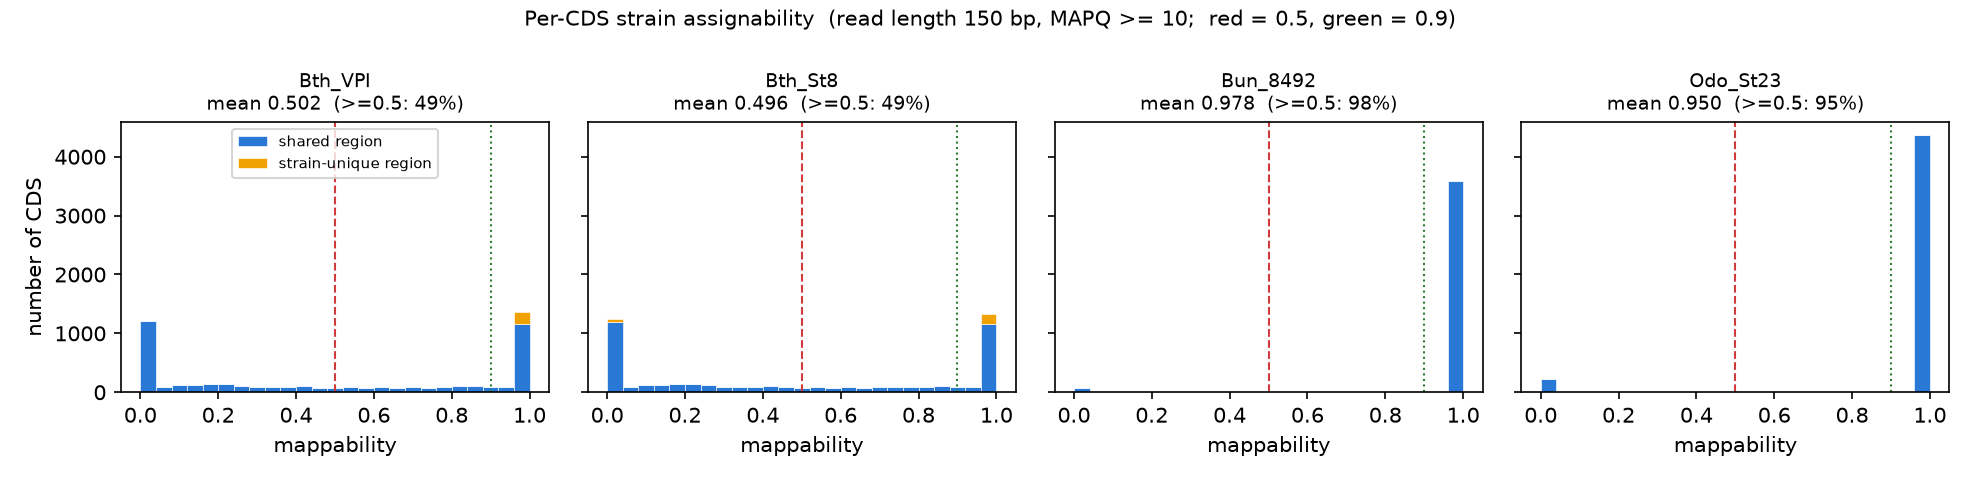

保存: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability/mappability_hist.pdf
  複製: 7 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability


In [21]:
# ── matplotlib の用意 ────────────────────────────────────────
#   ★ conda ではなく pip で入れる。
#     理由: `mamba install -n base matplotlib-base` を dry-run したところ、
#     libgcc 14.2.0→16.2.0 / libstdcxx 14.2.0→16.2.0 / openssl / zlib など
#     既存27パッケージが更新される。base には bakta が入れた blast・diamond・
#     hmmer のバイナリがあり、これらを壊す危険がある。
#     pip の wheel は conda の C ライブラリに触れず、7個を追加するだけで済む。
import importlib, subprocess, sys

try:
    import matplotlib
except ImportError:
    print("matplotlib が無いので pip で導入します（既存パッケージは変更されない）...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib"],
                   check=False)
    importlib.invalidate_caches()        # 新しい site-packages を認識させる
    import matplotlib

matplotlib.use("Agg")                    # GUI を使わない（notebook は inline 表示）
import matplotlib.pyplot as plt
print("matplotlib", matplotlib.__version__)

# ── mappability の分布を描く ─────────────────────────────────
#   ★ 図中の文字は英語にする。matplotlib の既定フォントに日本語が無く、
#     PDF に埋め込むと文字化けするため（CLAUDE.md の作図ルールと同じ方針）
mp = pd.read_csv(MAP_DIR / "cds_mappability_annotated.tsv", sep="\t")

fig, axes = plt.subplots(1, len(REF_STRAINS),
                         figsize=(3.3 * len(REF_STRAINS), 3.2), sharey=True)
if len(REF_STRAINS) == 1:
    axes = [axes]

for ax, sid in zip(axes, REF_STRAINS):
    sub = mp[mp.strain == sid]
    # 固有領域と共通領域を積み上げで色分けする
    shared = sub.loc[sub["領域"] == "共通領域", "mappability"]
    unique = sub.loc[sub["領域"] == "固有領域", "mappability"]
    ax.hist([shared, unique], bins=25, range=(0, 1), stacked=True,
            color=["#2a78d6", "#f0a202"], edgecolor="white", linewidth=0.3,
            label=["shared region", "strain-unique region"])
    ax.axvline(0.5, color="#d03b3b", lw=1, ls="--")
    ax.axvline(0.9, color="#2e7d32", lw=1, ls=":")
    ax.set_title(f"{sid}\nmean {sub.mappability.mean():.3f}  "
                 f"(>=0.5: {100*(sub.mappability>=0.5).mean():.0f}%)", fontsize=9)
    ax.set_xlabel("mappability")

axes[0].set_ylabel("number of CDS")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle(f"Per-CDS strain assignability  (read length {READLEN} bp, "
             f"MAPQ >= {MAPQ_MIN};  red = 0.5, green = 0.9)", fontsize=10)
fig.tight_layout()

pdf = MAP_DIR / "mappability_hist.pdf"
png = MAP_DIR / "mappability_hist.png"
fig.savefig(pdf)                 # ベクタ（論文用）
fig.savefig(png, dpi=150)        # notebook 表示用
plt.close(fig)

from IPython.display import Image, display as _disp
_disp(Image(filename=str(png)))
print("保存:", pdf)
_ = archive_to_project(MAP_DIR, quiet=True)

---
### mappability の読み方（重要。誤解しやすい）

**向きに注意。** mappability は「そのCDSに何が当たったか（入ってくる側）」ではなく、
**「そのCDSから作った擬似リードが、どこへ行ったか（出ていく側）」**の指標。

```
mappability = n_unique / n_sim

n_sim    = そのCDSから切り出した擬似リードの本数
n_unique = そのうち MAPQ >= 10 だった本数（＝株を特定できた本数）
```

**分母も分子も、そのCDS自身から作ったリードだけ。** 他の菌のリードは一切関与しない。

#### 具体例

Bth_VPI のある CDS（1,000 bp）から 10 bp 刻みで 86 本の擬似リードを作った場合:

```
CDS (Bth_VPI, 1000 bp)
├── 前半500 bp：St8 と配列が同一 ──┤── 後半500 bp：St8 と10箇所違う ──┤
   ↓ 150 bp を 10 bp 刻みで切る
   リード 1〜43 本（前半由来）→ VPI にも St8 にも完全一致 → MAPQ 0〜1 → 一意でない
   リード44〜86 本（後半由来）→ VPI にのみ一致          → MAPQ 42   → 一意

   mappability = 43 / 86 = 0.5
```

**0.5 とは「そのCDSの約半分の長さでは株を区別できるが、残り半分では区別できない」**という意味。
「50%が別の菌だった」ではない。

| 値 | 意味 |
|---|---|
| **1.0** | そのCDSの**どの位置から切ったリードでも**株を特定できる。相手株に対応配列が無いか、全長にわたって十分な塩基差がある |
| **0.5** | CDSの半分の長さでは特定でき、半分ではできない。保存ドメインと可変ドメインが混在している典型 |
| **0** | **どの位置のリードも**他の株と区別がつかない。配列がほぼ完全に同一 |

#### 「間違った株に当たる」ことは起きない

擬似リードは自分のゲノムの**部分配列そのもの**なので、自分の位置には必ず完全一致で当たる。

| 状況 | 結果 |
|---|---|
| 自分だけ完全一致、他は不一致 | MAPQ 高 → **一意**（mappability に加算） |
| 自分も他株も完全一致（**同点**） | MAPQ 0〜1 → 一意でない |

同点のとき bowtie2 は同点の中から1つをランダムに代表として報告する。それがたまたま別株
だった場合に `top_confused_with` に記録される。**「取り違えた」のではなく「区別がつかなかった」。**

#### 実データでの意味

本番のマッピングでは、リードがどの株から来たかは分からない。mappability が低い CDS に
当たったリードは bowtie2 が MAPQ を下げ、`featureCounts --fraction -M` では 1/2 ずつ
両株に配分される。つまりカウントが「VPI と St8 の混合」になる。

**群間比較（W vs K）では両群に等しく効くので偽陽性は作らないが、株間の差は論じられない。**
これが CLAUDE.md §3 の論点。

## セル19-2: 1つの CDS で、位置ごとに区別可能性を見る

セル16 は CDS 単位に集計して位置情報を捨てている。ここでは**1遺伝子だけ取り出して
擬似リードを作り直し、位置 → MAPQ を記録する**。
mappability が「CDS のどの部分が区別できるか」を表していることの確認。

例として `Bth_VPI` / `BT_RS00805`（mappability ≈ 0.50、551 リード）を使う。
**セル16 の集計値と一致すれば、計算が正しいことの検算にもなる。**

`EXAMPLE_STRAIN` / `EXAMPLE_GENE` を書き換えれば、任意の遺伝子で同じ図を描ける。

Bth_VPI / BT_RS00805
  product : alpha-2-macroglobulin
  長さ    : 5,650 bp


  擬似リード 551 本中、一意 275 本 → mappability = 0.499
  （セル16の集計値と一致するはず）

  MAPQ の分布:


,MAPQ,リード数
0,1,147
1,6,129
2,30,164
3,31,43
4,32,33
5,34,9
6,35,21
7,36,4
8,37,1


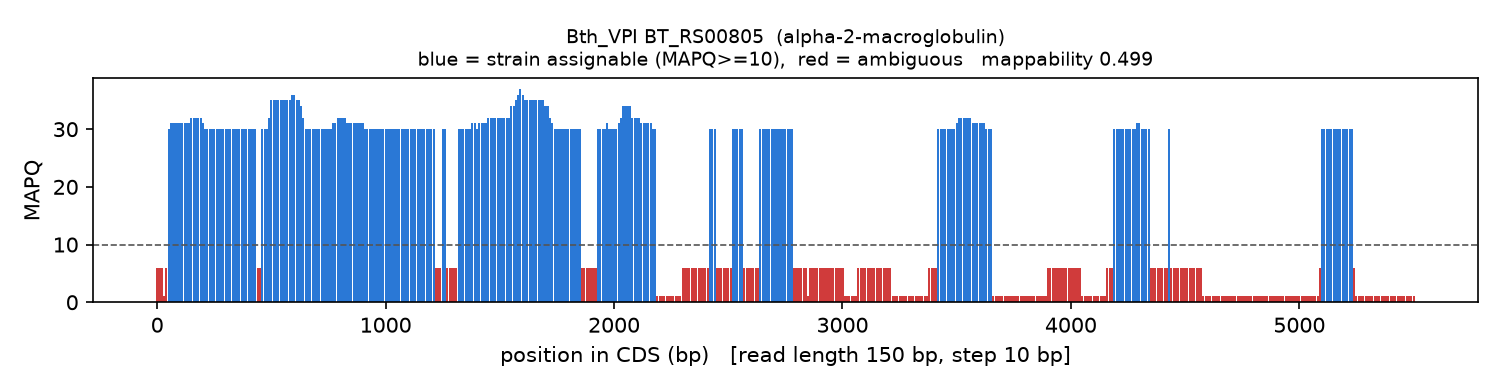


株を区別できない区間（8 箇所 / 計 4,130 bp = CDS の 73%）:
  CDS     0 –   190 bp  (  190 bp)
  CDS   440 –   600 bp  (  160 bp)
  CDS 1,220 – 1,460 bp  (  240 bp)
  CDS 1,860 – 2,070 bp  (  210 bp)
  CDS 2,190 – 2,780 bp  (  590 bp)
  CDS 2,790 – 3,560 bp  (  770 bp)
  CDS 3,660 – 4,330 bp  (  670 bp)
  CDS 4,350 – 5,650 bp  (1,300 bp)

→ mappability は「CDS のどの部分が区別できるか」を表している。
   保存度の高いドメインは区別できず、分岐した領域では区別できる。
  複製: 9 ファイル → /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/mappability


In [22]:
import gzip, tempfile

# ── 1つの CDS を取り出して、位置ごとに「株を特定できたか」を見る ──
#   セル16 は CDS 単位に集計して位置情報を捨てている。ここでは1遺伝子だけ
#   取り出して擬似リードを作り直し、位置 → MAPQ を記録する。
#   mappability が「CDS のどの部分が区別できるか」を表していることの確認。
EXAMPLE_STRAIN = "Bth_VPI"
EXAMPLE_GENE   = "BT_RS00805"      # mappability ≈ 0.50 の例（セル18の表から選択）

# ── その CDS の配列と product を取り出す ─────────────────────
seq, product = None, "?"
with gzip.open(ANNO[EXAMPLE_STRAIN]["cds"], "rt") as f:
    keep, buf = False, []
    for line in f:
        if line.startswith(">"):
            if keep:
                break
            keep = f"[locus_tag={EXAMPLE_GENE}]" in line
            if keep:
                m = re.search(r"\[protein=([^\]]+)\]", line)
                product = m.group(1) if m else "?"
        elif keep:
            buf.append(line.strip())
    seq = "".join(buf)

print(f"{EXAMPLE_STRAIN} / {EXAMPLE_GENE}")
print(f"  product : {product}")
print(f"  長さ    : {len(seq):,} bp")

# ── 擬似リードを作り直して、位置ごとの MAPQ を取る ────────────
with tempfile.NamedTemporaryFile("w", suffix=".fa", delete=False) as tf:
    for i in range(0, max(1, len(seq) - READLEN + 1), STEP):
        tf.write(f">pos{i}\n{seq[i:i+READLEN]}\n")
    tmp_fa = tf.name

cmd = (f"{tool_path('bowtie2')} -f -x {idx} -U {tmp_fa} -p 4 --no-unal "
       f"2>/dev/null | {tool_path('samtools')} view -")
res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
Path(tmp_fa).unlink()

rows = []
for line in res.stdout.splitlines():
    p = line.split("\t", 6)
    if len(p) < 5:
        continue
    rows.append({"pos": int(p[0][3:]),
                 "mapq": int(p[4]),
                 "hit_strain": p[2].split("~", 1)[0]})
pos = pd.DataFrame(rows).sort_values("pos").reset_index(drop=True)
pos["一意"] = pos.mapq >= MAPQ_MIN

print(f"  擬似リード {len(pos)} 本中、一意 {pos['一意'].sum()} 本 "
      f"→ mappability = {pos['一意'].mean():.3f}")
print(f"  （セル16の集計値と一致するはず）")
print()
print("  MAPQ の分布:")
show(pos.mapq.value_counts().sort_index().rename_axis("MAPQ")
        .reset_index(name="リード数"))

# ── 位置ごとに図示する ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.bar(pos.pos, pos.mapq, width=STEP * 0.9,
       color=["#2a78d6" if u else "#d03b3b" for u in pos["一意"]])
ax.axhline(MAPQ_MIN, color="#555", lw=0.8, ls="--")
ax.set_xlabel(f"position in CDS (bp)   [read length {READLEN} bp, step {STEP} bp]")
ax.set_ylabel("MAPQ")
ax.set_title(f"{EXAMPLE_STRAIN} {EXAMPLE_GENE}  ({product[:55]})\n"
             f"blue = strain assignable (MAPQ>={MAPQ_MIN}),  red = ambiguous   "
             f"mappability {pos['一意'].mean():.3f}", fontsize=9)
fig.tight_layout()
out_png = MAP_DIR / f"example_{EXAMPLE_STRAIN}_{EXAMPLE_GENE}.png"
fig.savefig(out_png, dpi=150)
fig.savefig(MAP_DIR / f"example_{EXAMPLE_STRAIN}_{EXAMPLE_GENE}.pdf")
plt.close(fig)
_disp(Image(filename=str(out_png)))

# ── 区別できない区間をまとめて表示 ───────────────────────────
#   各リードは READLEN の幅を持つので、[pos, pos+READLEN) の区間として扱い、
#   重なるものをマージする（連続する位置を単純に繋ぐと区間が重複して見える）
iv = sorted((r.pos, min(r.pos + READLEN, len(seq)))
            for _, r in pos.iterrows() if not r["一意"])
runs = []
if iv:
    s0, e0 = iv[0]
    for a, b in iv[1:]:
        if a <= e0:          # 重なる → 伸ばす
            e0 = max(e0, b)
        else:
            runs.append((s0, e0)); s0, e0 = a, b
    runs.append((s0, e0))
print()
print(f"株を区別できない区間（{len(runs)} 箇所 / 計 "
      f"{sum(e - s for s, e in runs):,} bp = CDS の "
      f"{100*sum(e - s for s, e in runs)/len(seq):.0f}%）:")
for s0, e0 in runs:
    print(f"  CDS {s0:>5,} – {e0:>5,} bp  ({e0 - s0:>5,} bp)")
print()
print("→ mappability は「CDS のどの部分が区別できるか」を表している。")
print("   保存度の高いドメインは区別できず、分岐した領域では区別できる。")
_ = archive_to_project(MAP_DIR, quiet=True)

### 考察（セル16–19-2 / mappability）— ステージ1 完了

#### 結果

| 株 | CDS数 | 平均 | 高(≥0.9) | 可(0.5–0.9) | 困難(0.1–0.5) | 不能(<0.1) | 使える(≥0.5) |
|---|---|---|---|---|---|---|---|
| **Bth_VPI** | 4,801 | **0.502** | 1,489 | 878 | 1,068 | 1,366 | **49.3%** |
| **Bth_St8** | 4,795 | **0.496** | 1,463 | 872 | 1,063 | 1,397 | **48.7%** |
| Bun_8492 | 3,688 | 0.978 | 3,591 | 20 | 9 | 68 | 97.9% |
| Odo_St23 | 4,618 | 0.950 | 4,371 | 16 | 7 | 224 | 95.0% |

> **2026-10-20 更新。** Bun_8492 を complete genome（GCF_025147485.1）に差し替えて再計算した。
> 下記「Bun_8492 の差し替えによる変化」を参照。Bth 2株と Odo_St23 は実質変化なし
> （Bth_VPI の 高 が 1,484→1,489 と微増したのは、統合リファレンスから Bun の
> 重複配列が減ったため）。

#### ★ CLAUDE.md §3 の問いへの回答

> 固有領域の206 CDS しか使えないのか、共通領域の CDS も使えるのか

**答え: 共通領域から約2,150 CDS が追加で使える。合計で約2,350 CDS。**

| 株 | 領域 | CDS数 | 平均 mappability | 高(≥0.9) |
|---|---|---|---|---|
| Bth_VPI | 固有領域 | 206 | **0.993** | 204 |
| Bth_VPI | 共通領域 | 4,595 | 0.480 | **1,285** |
| Bth_St8 | 固有領域 | 230 | 0.795 | 182 |
| Bth_St8 | 共通領域 | 4,565 | 0.481 | **1,281** |

```
固有領域のみ（セル11の判定）    :   206 CDS
mappability >= 0.9（高信頼）    : 1,489 CDS   ← 7倍
mappability >= 0.5              : 2,367 CDS   ← 11倍
```

**「206個に限定」でも「数千個すべて使える」でもなく、その中間で約2,350個。**
ステージ5で株レベルの結論を出せる範囲が、固有領域だけの想定より一桁広い。

#### 分布は完全な二峰性（セル19の図）

平均 0.50 は「どのCDSも半々」という意味ではない。実態は
**ほぼ完全に区別できる CDS が約1,300個、全く区別できない CDS が約1,200個、中間は少数。**

これは実務上むしろ好都合で、**閾値を 0.5 に置いても 0.9 に置いてもほぼ同じ集合**が選ばれる。
閾値の置き方が結論を左右しない。

図では **固有領域（橙）が 1.0 の山の上端に乗っている**。固有領域は確かに区別できるが、
1.0 の山の大部分は共通領域の CDS である。
**「固有領域だから区別できる」のではなく「共通領域でも分岐が十分なら区別できる」。**

#### 検算が2つ通っている

1. **固有領域 206 CDS の平均 mappability = 0.993**（204個が ≥0.9）。
   相手株に配列が無い領域なので 1.0 に近くなるはず、という予測どおり。
   セル10-2（minimap2 ベース）とセル16（bowtie2 ベース）が独立な方法で整合
2. **セル19-2 で `BT_RS00805` を単独で測り直して 0.499**。セル16 の集計値 0.4991 と一致

#### ★ Bun_8492 の差し替えによる変化（2026-10-20）

`1_genome_copy.ipynb` セル5 で Bun_8492 を **GCF_000154205.1（Scaffold、33配列）→
GCF_025147485.1（Complete Genome、1配列）** に差し替え、このnotebookを再実行した。

| 項目 | 旧（Scaffold） | 新（Complete） |
|---|---|---|
| contig数 | 33 | **1** |
| 全長 | 4,719,429 bp | 4,629,452 bp |
| N塩基（ギャップ） | あり | **0** |
| CDS 数 | 3,795 | **3,688**（107減） |
| 平均 mappability | 0.963 | **0.978** |
| 高(≥0.9) | 3,619 | 3,591 |
| **不能(<0.1)** | **109** | **68**（38%減） |
| 使える(≥0.5) | 96.3% | **97.9%** |

**これで「不能」の原因が切り分けられた。**

- **41 CDS 分は contig 端・N ギャップ由来**だった（complete genome 化で解消）
- **残る 68 CDS は配列そのものの問題。** 混同相手の表で `Bun_8492 ↔ Bth_VPI` が 28 CDS
  あることから、**可動性遺伝因子の共有**（*Bacteroides* 属内での ICE / トランスポゾンの
  水平伝達）が主因と考えられる

CDS が 107 減ったのは、Scaffold 側にあった重複・断片化した CDS が解消したため。
**ゲート1の判定は変わらない**（Bun_8492 は近縁ペアを持たないため）。

#### 予想外の所見: 科をまたぐ混同

| 混同 | CDS数 | 関係 |
|---|---|---|
| Bth_St8 ↔ Bth_VPI | 2,311 | 同種（想定どおり） |
| **Odo_St23 ↔ Bth_St8** | **73 / 71** | **★科が違う** |
| Bun_8492 ↔ Bth_VPI | 28 | 同属別種 |

*Odoribacteraceae* と *Bacteroides* は科が異なるのに 70個以上の CDS が区別できない。
**可動性遺伝因子の共有**が原因と考えられる（セル10-2 で Bth_St8 に 117 kb の ICE を検出済み）。

Bun_8492 と Odo_St23 のヒストグラムに見える 0 付近の小さな山（68・224 CDS）がこれに対応する。
**ICE 上の遺伝子で「どの菌が接合伝達機構を発現しているか」を論じるときは、
mappability を確認してからにする。**

#### Bth_St8 の固有領域に45個の「不能」（要確認）

Bth_St8 の固有領域 230 CDS のうち **45個が mappability < 0.1**。Bth_VPI 側は0個で非対称。

原因として疑わしいのは **117 kb の ICE**。ICE やプラスミド上の遺伝子は
トランスポザーゼ・リコンビナーゼなど**同じ株のゲノム内に類似配列が複数ある**ことが多く、
「相手株には無い」のに「自株内で曖昧」になって MAPQ が下がる。
`cds_mappability_annotated.tsv` と `unique_regions/Bth_St8_unique_vs_Bth_VPI.tsv` を
突き合わせれば同定できる。ステージ5で引っかかる可能性があるので要確認。

#### ステージ3以降への申し送り

1. **GTF の属性に `mappability` を持たせる**（CLAUDE.md §7 のとおり）。
   株レベルの所見を出すたびに、その遺伝子が区別可能だったかを確認できるようにする
2. **株レベルの DE 解析（(B) 株ごと DESeq2）では mappability >= 0.5 の CDS に限定する。**
   Bth 2株では約2,350 CDS、Bun_8492・Odo_St23 ではほぼ全 CDS
3. **群間比較（W vs K）では mappability が低い CDS も使える。**
   取り違えは両群に等しくかかるので偽陽性は作らない（効果量は減衰する）。
   ただし **VPI : St8 の存在比が両群で大きく変わらないこと**が前提（CLAUDE.md ステージ4 で確認）
4. **Salmon の EM は mappability が低い CDS で特に効く。** featureCounts の 1/NH 等分と
   相関を取り、乖離の大きい遺伝子にフラグを立てる（CLAUDE.md §7 ステージ3）

---

**ステージ1（リファレンスQC）完了。** ゲート1の判定と mappability の実測が揃った。
次はステージ2（`3_build_reference.ipynb`）。

---
# 追記（2026-10-20）: Bun_8492 のゲノム差し替えに伴う再計算

`1_genome_copy.ipynb` セル5 で Bun_8492 を差し替えた。

| 項目 | 旧 | 新 |
|---|---|---|
| accession | GCF_000154205.1 (ASM15420v1) | **GCF_025147485.1 (ASM2514748v1)** |
| level | Scaffold（33配列、Nギャップあり） | **Complete Genome（1配列）** |
| 全長 | 4,719,429 bp | 4,629,452 bp |
| locus_tag | `BACUNI_RS*` | `NQ510_*` |

## セル20: 古い結果を消す

このnotebookの各セルは**「結果が既にあればスキップ」**するので、古い結果を消さないと
**Bun_8492 だけ旧ゲノムの数字が残り続ける**。

消すのは Bun_8492 を含む計算の出力だけ。
**`ani/unique_regions/` は残す**（FOCUS_PAIRS = Bth ペアと Odo ペアのみを扱っており、
Bun_8492 を含まないため）。

`CLEAN_STALE = False` にすると、削除せず一覧表示だけになる。

### 期待される変化

| セル | 変化 |
|---|---|
| セル11（ゲート1） | **判定は変わらない**。Bun_8492 は近縁ペアを持たない |
| セル13（統合リファレンス） | contig 44 → **12** になるはず |
| セル17（mappability） | **Bun_8492 が改善するか**。旧版では「不能(<0.1)」が 109 CDS あった |

削除後、セルを順に再実行する（所要時間の大半は bowtie2 index と擬似リードのマップ）。

In [23]:
# ── このセルで使うもの（セル単体でも実行できるように、ここで定義する）──────
#   セル1・セル2 を実行していなくても動く。値はセル1と同じ
from pathlib import Path
import pandas as pd

ROOT    = Path("/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome")
PROJECT = Path("/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome")
ANI_DIR = ROOT/"ani"; REF_DIR = ROOT/"ref"; MAP_DIR = ROOT/"mappability"

try:                                   # セル2を実行済みなら show() を使う
    show
except NameError:
    pd.set_option("display.unicode.east_asian_width", True)
    pd.set_option("display.max_rows", 200); pd.set_option("display.width", 200)
    def show(df, title=None):
        if title: print(title)
        try:
            from IPython.display import display; display(df)
        except ImportError:
            print(df.to_string(index=False))

# ── Bun_8492 差し替えに伴う再計算（2026-10-20）────────────────
#   1_genome_copy.ipynb セル5 で Bun_8492 を
#     GCF_000154205.1 (Scaffold, 33配列) → GCF_025147485.1 (Complete, 1配列)
#   に差し替えた。このnotebookの各セルは「結果が既にあればスキップ」するので、
#   古い結果を消さないと Bun_8492 だけ旧ゲノムの数字が残り続ける。
#
#   消す対象は Bun_8492 を含む計算の出力だけ。
#   ani/unique_regions/ は FOCUS_PAIRS（Bth ペアと Odo ペア）のみを扱っており
#   Bun_8492 を含まないので残す。
CLEAN_STALE = False       # ★ 2026-10-20 に実行済み（31ファイル削除）。
                          #   再実行時に消さないよう False にしてある。
                          #   またゲノムを差し替えたときだけ True に戻す

stale = []
# ANI（全ペア総当たりなので Bun を含む）
stale += [ANI_DIR/"fastani_all.tsv", ANI_DIR/"skani_all.tsv",
          ANI_DIR/"ani_summary.tsv", ANI_DIR/"unique_sequence.tsv",
          ANI_DIR/"gate1_summary.tsv", ANI_DIR/"genome_list.txt"]
# PAF（Bun_8492 が query か target のもの）
stale += [p for p in ANI_DIR.glob("*_vs_*.paf") if "Bun_8492" in p.name]
# 統合リファレンスと index（Bun_8492 を含む）
stale += [REF_DIR/"oligo4_bacteria.fna"] + sorted(REF_DIR.glob("oligo4_bacteria*.bt2*"))
# mappability（統合リファレンスに依存）
stale += sorted(MAP_DIR.glob("*"))

stale = [p for p in stale if p.exists()]
df_stale = pd.DataFrame([{"path": str(p.relative_to(ROOT)),
                          "MB": round(p.stat().st_size/1e6, 2)} for p in stale])
show(df_stale, f"旧ゲノムに基づく出力（{len(stale)} ファイル / "
               f"{sum(p.stat().st_size for p in stale)/1e9:.2f} GB）")

print()
print("残すもの: ani/unique_regions/ （FOCUS_PAIRS のみで Bun_8492 を含まない）")
print()
if CLEAN_STALE:
    for p in stale:
        p.unlink()
    print(f"{len(stale)} ファイルを削除しました")
    # PROJECT 側の複製も古いので消す（次の実行で作り直される）
    for d in ("ani", "mappability"):
        for p in sorted((PROJECT/d).rglob("*")) if (PROJECT/d).exists() else []:
            if p.is_file() and "unique_regions" not in str(p):
                p.unlink()
    print("PROJECT 側の複製も削除しました（unique_regions は残す）")
else:
    print("CLEAN_STALE = False のため削除していません")

print()
print("=" * 72)
print("再実行する順序")
print("=" * 72)
print("""
  セル1   設定（ROOT 等）
  セル2   ヘルパー（show / archive_to_project）
  セル6   入力ゲノムの確認   ← Bun_8492 が 1 contig になっていることを確認
  セル7   fastANI + skani    ← 再計算（数分）
  セル8   ANI の表示
  セル9   minimap2           ← Bun_8492 絡みの 8 ペアのみ再計算
  セル10  一意配列量
  セル10-2 固有配列の詳細     ← FOCUS_PAIRS のみなので実質変化なし
  セル11  ゲート1の判定       ← 判定は変わらないはず（Bun は近縁ペアを持たない）
  セル12  既存アノテーション  ← ★ Bun_8492 の GFF が新しいものに変わる
  セル13  統合リファレンス    ← 44 contig → 12 contig になるはず
  セル14  bowtie2 index
  セル15  擬似リード
  セル16  マップして集計
  セル17  株ごとのサマリー    ← ★ Bun_8492 の mappability が改善するか確認
  セル18  領域別
  セル19  ヒストグラム
""")
print("※ セル12 は provenance.tsv の src_path を見るので、")
print("   1_genome_copy.ipynb セル5 で更新済みなら自動で新しい GFF を指す。")

旧ゲノムに基づく出力（31 ファイル / 0.39 GB）


,path,MB
0,ani/fastani_all.tsv,0.00
1,ani/skani_all.tsv,0.00
2,ani/ani_summary.tsv,0.00
3,ani/unique_sequence.tsv,0.00
4,ani/gate1_summary.tsv,0.00
5,ani/genome_list.txt,0.00
6,ani/Bth_St8_vs_Bun_8492.paf,0.04
7,ani/Bth_VPI_vs_Bun_8492.paf,0.04
8,ani/Bun_8492_vs_Bth_St8.paf,0.04
9,ani/Bun_8492_vs_Bth_VPI.paf,0.04



残すもの: ani/unique_regions/ （FOCUS_PAIRS のみで Bun_8492 を含まない）

CLEAN_STALE = False のため削除していません

再実行する順序

  セル1   設定（ROOT 等）
  セル2   ヘルパー（show / archive_to_project）
  セル6   入力ゲノムの確認   ← Bun_8492 が 1 contig になっていることを確認
  セル7   fastANI + skani    ← 再計算（数分）
  セル8   ANI の表示
  セル9   minimap2           ← Bun_8492 絡みの 8 ペアのみ再計算
  セル10  一意配列量
  セル10-2 固有配列の詳細     ← FOCUS_PAIRS のみなので実質変化なし
  セル11  ゲート1の判定       ← 判定は変わらないはず（Bun は近縁ペアを持たない）
  セル12  既存アノテーション  ← ★ Bun_8492 の GFF が新しいものに変わる
  セル13  統合リファレンス    ← 44 contig → 12 contig になるはず
  セル14  bowtie2 index
  セル15  擬似リード
  セル16  マップして集計
  セル17  株ごとのサマリー    ← ★ Bun_8492 の mappability が改善するか確認
  セル18  領域別
  セル19  ヒストグラム

※ セル12 は provenance.tsv の src_path を見るので、
   1_genome_copy.ipynb セル5 で更新済みなら自動で新しい GFF を指す。
